# Time-series ML: Forecasting

You’ll want to reduce the data set to only one location, the Kensington and Chelsea location.
You’ll want to look at only one pollutant, Nitrogen Dioxide (NO2).
You’ll find it easier to work with daily averages than hourly (anyone remember .resample()?).
Do you need to fill in any missing values?


## Imports

In [1]:
import itertools
import numpy as np
import pandas as pd
import pathlib
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from typing import Literal
import openmeteo_requests
import requests_cache
from retry_requests import retry



In [2]:
plt.style.use('seaborn-v0_8-dark-palette')

In [3]:
print(plt.style.available)

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


## Data-exploration


loading the data


In [4]:
project = pathlib.Path().cwd()
filepath = pathlib.Path(project / "data" / "london_air_quality_2010_2023_top5_sites.csv")

data = pd.read_csv(filepath)

inspect the data

In [5]:
data.head()

,datetime,LocalAuthorityCode,LocalAuthorityName,SiteCode,SiteName,SiteType,Latitude,Longitude,co_level,no2_level,o3_level,pm10_level,pm25_level,so2_level
0,2010-01-01 00:00:00,6,Camden,BL0,Camden - Bloomsbury,Urban Background,51.522287,-0.125848,NaN,54.8,20.6,16.0,16.0,1.8
1,2010-01-01 01:00:00,6,Camden,BL0,Camden - Bloomsbury,Urban Background,51.522287,-0.125848,0.2,51.0,21.3,13.0,15.0,0.0
2,2010-01-01 02:00:00,6,Camden,BL0,Camden - Bloomsbury,Urban Background,51.522287,-0.125848,0.2,49.2,23.4,10.0,9.0,0.0
3,2010-01-01 03:00:00,6,Camden,BL0,Camden - Bloomsbury,Urban Background,51.522287,-0.125848,0.1,43.0,27.4,10.0,9.0,0.0
4,2010-01-01 04:00:00,6,Camden,BL0,Camden - Bloomsbury,Urban Background,51.522287,-0.125848,0.1,39.7,29.4,9.0,8.0,0.7


In [6]:
data.columns

Index(['datetime', 'LocalAuthorityCode', 'LocalAuthorityName', 'SiteCode',
       'SiteName', 'SiteType', 'Latitude', 'Longitude', 'co_level',
       'no2_level', 'o3_level', 'pm10_level', 'pm25_level', 'so2_level'],
      dtype='str')

In [7]:
data['SiteName'].unique()

<StringArray>
[                   'Camden - Bloomsbury',
          'Ealing - Hanger Lane Gyratory',
     'Kensington and Chelsea - North Ken',
          'Westminster - Marylebone Road',
 'Richmond Upon Thames - Barnes Wetlands']
Length: 5, dtype: str

In [8]:
print(f'We have {data.shape[0]} rows and {data.shape[1]} columns in the full dataframe')



We have 600685 rows and 14 columns in the full dataframe


We are going to filter the data to the area of london that is the scope for this project:

In [9]:
area = 'Camden - Bloomsbury'
data = data.loc[data["SiteName"] == area]
print(f'We have {data.shape[0]} rows and {data.shape[1]} columns in the filtered area of the Camden - Bloomsbury')

We have 117954 rows and 14 columns in the filtered area of the Camden - Bloomsbury


further we are only focussing on 1 pollutant which is NO2, so i`m going to drop the other ones. before doing the dropping operation I will take a look if any further columns are redundant because of the filtering.


Longitude, Latitude, SiteType, SiteCode, LocalAuthorityName and LocalAuthorityCode are all location bound and the same over all the filtered rows. I will drop these columns as well as the pollutants that are out of scope: co_level, o3_level, pm10_level, pm25_level, so2_level


In [10]:
print(data.columns)

Index(['datetime', 'LocalAuthorityCode', 'LocalAuthorityName', 'SiteCode',
       'SiteName', 'SiteType', 'Latitude', 'Longitude', 'co_level',
       'no2_level', 'o3_level', 'pm10_level', 'pm25_level', 'so2_level'],
      dtype='str')


In [11]:
def extract_location(data):

    long = data[['Longitude', 'Latitude']].iloc[0,0]
    lat = data[['Longitude', 'Latitude']].iloc[0,1]

    print(lat)
    print(long)

    return lat, long






location extraction as further down the notebook we will need this.

In [12]:
location = extract_location(data)

51.522287
-0.125848


In [13]:
data = data[['datetime', 'no2_level']]

In [14]:
data.head()

,datetime,no2_level
0,2010-01-01 00:00:00,54.8
1,2010-01-01 01:00:00,51.0
2,2010-01-01 02:00:00,49.2
3,2010-01-01 03:00:00,43.0
4,2010-01-01 04:00:00,39.7


In [15]:
data.describe()

,no2_level
count,111811.000000
mean,40.685758
std,22.650665
min,0.400000
25%,22.600000
50%,37.600000
75%,55.700000
max,206.600000


lets inspect the data types of our 2 remaining columns.

In [16]:
data.dtypes

datetime         str
no2_level    float64
dtype: object

lets transform the datetime to datetime object and sort it.

In [17]:
data['datetime'] = pd.to_datetime(data['datetime'])

data = data.set_index('datetime')
data = data.sort_index()





further we are going to resample the time from hourly to daily.

In [18]:
data = data.resample("D").mean()

In [19]:
print(f"The earliest data in our data: {data.index.min()}")
print(f"The latest data in the data: {data.index.max()}")

The earliest data in our data: 2010-01-01 00:00:00
The latest data in the data: 2023-08-21 00:00:00


lets see if we have missin measurement values.

In [20]:
data.isna().sum()

no2_level    258
dtype: int64

We have 258 missing values in our timeseries. before I decide how to solve this problem, I'm going to check how big the missing gaps are.

In [21]:
def check_gaps(data):

    missing = data[data["no2_level"].isna() == True].index.tolist()

    if len(missing) == 0:
        return print('There are no missing values in the set')

    start = missing[0]
    previous = missing[0]
    gap_list = []

    for date in missing[1:]:

        if date - previous > pd.Timedelta(days=1):
            days = (previous - start).days + 1
            gap_list.append(f"{start} to {previous}: {days} days")

            start = date

        previous = date

    days = (previous - start).days + 1
    gap_list.append(f"{start} to {previous}: {days} days")


    return gap_list


In [22]:
check_gaps(data)

['2010-12-31 00:00:00 to 2010-12-31 00:00:00: 1 days',
 '2011-02-15 00:00:00 to 2011-02-21 00:00:00: 7 days',
 '2011-12-31 00:00:00 to 2011-12-31 00:00:00: 1 days',
 '2012-06-28 00:00:00 to 2012-07-16 00:00:00: 19 days',
 '2012-12-31 00:00:00 to 2012-12-31 00:00:00: 1 days',
 '2013-08-01 00:00:00 to 2013-08-01 00:00:00: 1 days',
 '2013-12-31 00:00:00 to 2013-12-31 00:00:00: 1 days',
 '2014-10-01 00:00:00 to 2014-12-31 00:00:00: 92 days',
 '2015-02-26 00:00:00 to 2015-02-26 00:00:00: 1 days',
 '2015-08-05 00:00:00 to 2015-08-05 00:00:00: 1 days',
 '2015-12-31 00:00:00 to 2015-12-31 00:00:00: 1 days',
 '2016-12-31 00:00:00 to 2016-12-31 00:00:00: 1 days',
 '2017-08-17 00:00:00 to 2017-08-17 00:00:00: 1 days',
 '2017-12-31 00:00:00 to 2017-12-31 00:00:00: 1 days',
 '2018-12-31 00:00:00 to 2018-12-31 00:00:00: 1 days',
 '2019-07-25 00:00:00 to 2019-07-29 00:00:00: 5 days',
 '2019-12-31 00:00:00 to 2019-12-31 00:00:00: 1 days',
 '2020-07-25 00:00:00 to 2020-07-26 00:00:00: 2 days',
 '2020-0

it seems that we have mostly just 1 day missing but further also 7 instances with 7 days or more. for the 1 day gaps I will use interpolate.

In [23]:
mask = ((data["no2_level"].isna() == True) & (data["no2_level"].shift(1).isna() == False) & (data["no2_level"].shift(-1).isna() == False))


In [24]:
data.loc[mask, "no2_level"] = data["no2_level"].interpolate(method="time").loc[mask]

In [25]:
data.loc[mask]

,no2_level
datetime,
2010-12-31,53.591667
2011-12-31,42.733333
2012-12-31,46.175272
2013-08-01,15.728977
2013-12-31,30.385417
2015-02-26,57.560455
2015-08-05,28.564205
2015-12-31,38.187500
2016-12-31,42.585417


In [26]:
check_gaps(data)

['2011-02-15 00:00:00 to 2011-02-21 00:00:00: 7 days',
 '2012-06-28 00:00:00 to 2012-07-16 00:00:00: 19 days',
 '2014-10-01 00:00:00 to 2014-12-31 00:00:00: 92 days',
 '2019-07-25 00:00:00 to 2019-07-29 00:00:00: 5 days',
 '2020-07-25 00:00:00 to 2020-07-26 00:00:00: 2 days',
 '2020-08-15 00:00:00 to 2020-08-17 00:00:00: 3 days',
 '2020-09-16 00:00:00 to 2020-09-29 00:00:00: 14 days',
 '2020-10-01 00:00:00 to 2020-11-25 00:00:00: 56 days',
 '2021-10-13 00:00:00 to 2021-10-14 00:00:00: 2 days',
 '2022-03-24 00:00:00 to 2022-03-29 00:00:00: 6 days',
 '2022-04-21 00:00:00 to 2022-05-15 00:00:00: 25 days',
 '2022-08-04 00:00:00 to 2022-08-14 00:00:00: 11 days']

The 1 day gaps have been interpolated. I still have multiple bigger gaps in the dataset but for forecasting not the whole dataset might be necessary. I will plot out the years and take a look at them. I decided to experiment with rolling mean windows as the day to day data is quite noisy.

In [27]:
plt.rcParams.update({
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.5,
    "grid.linewidth": 0.8,
    "grid.color": "lightgray",
})

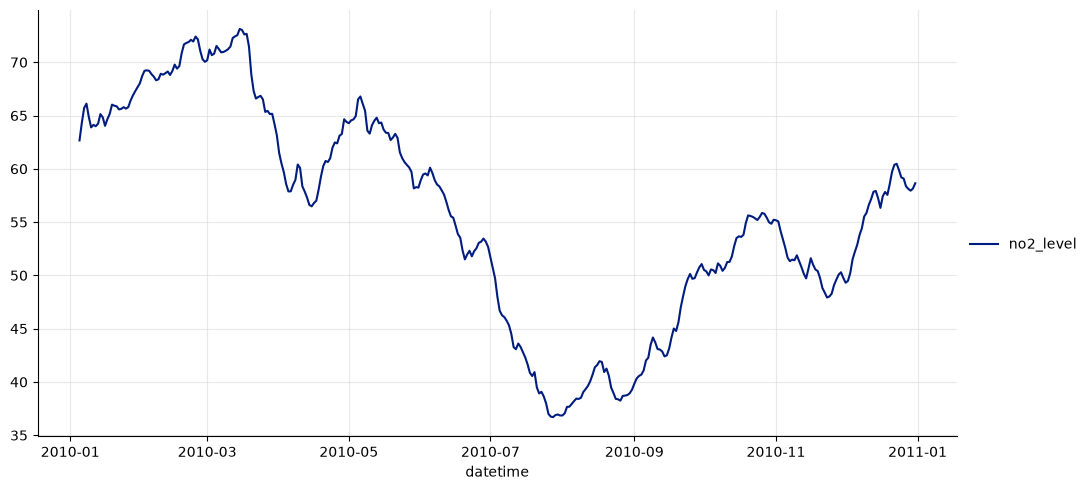

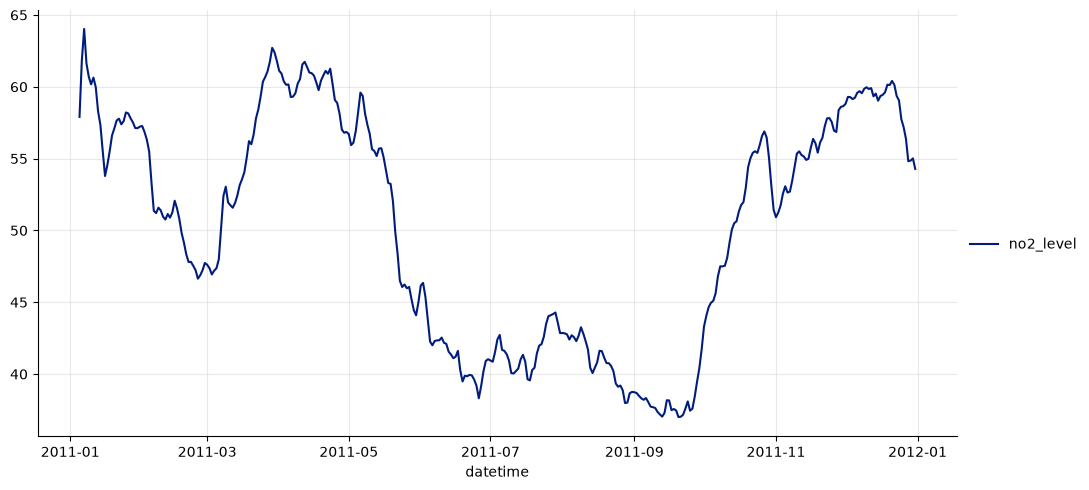

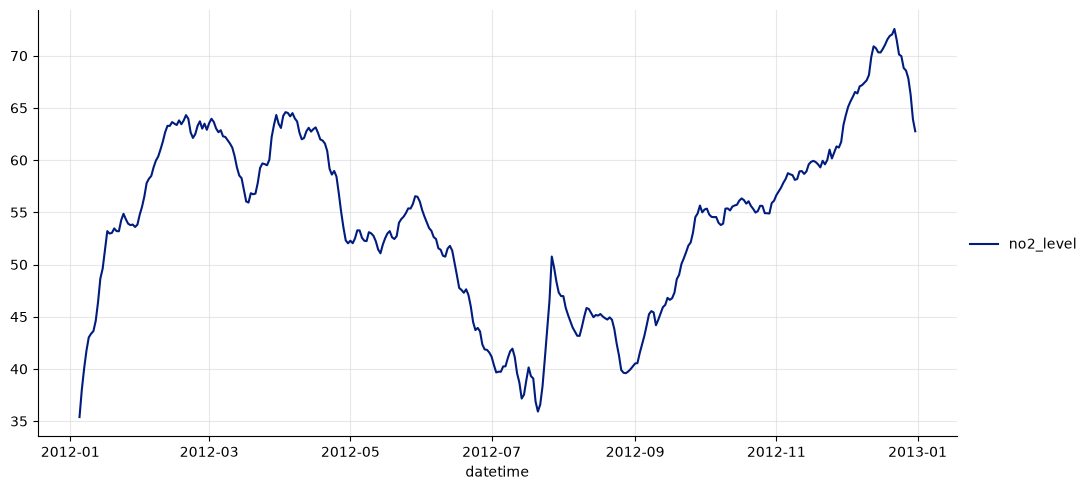

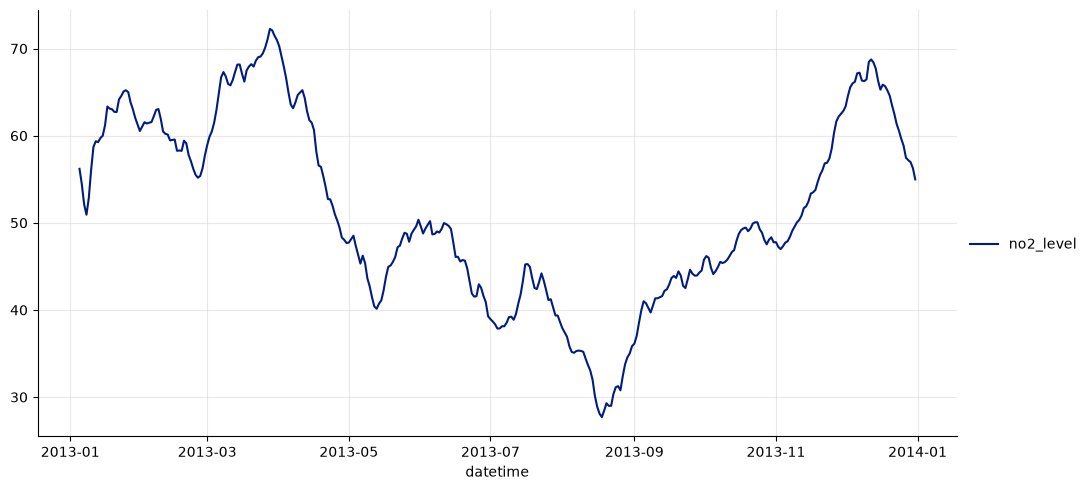

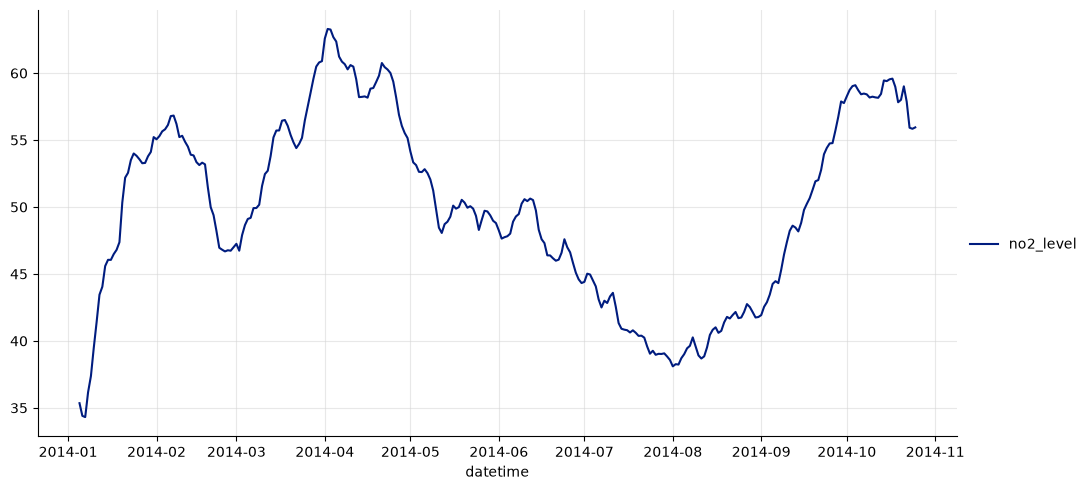

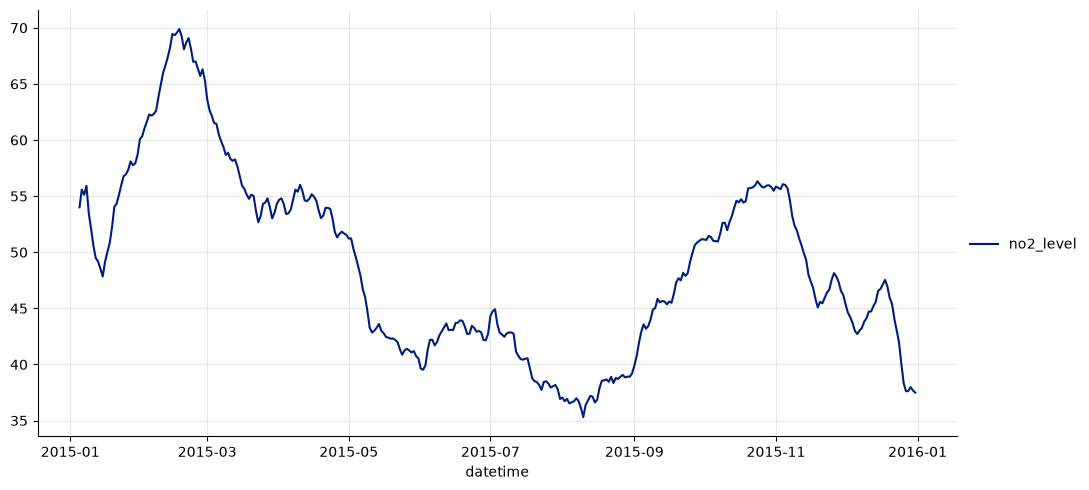

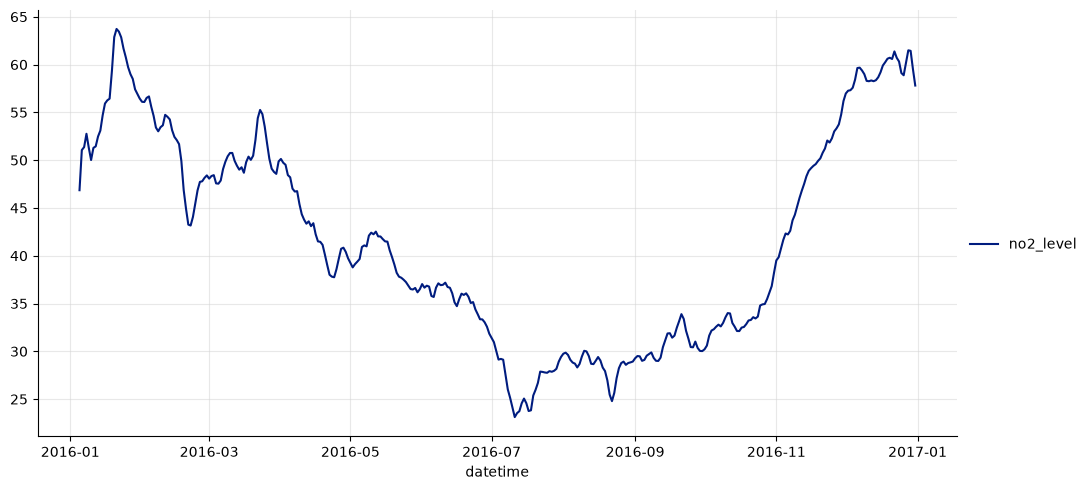

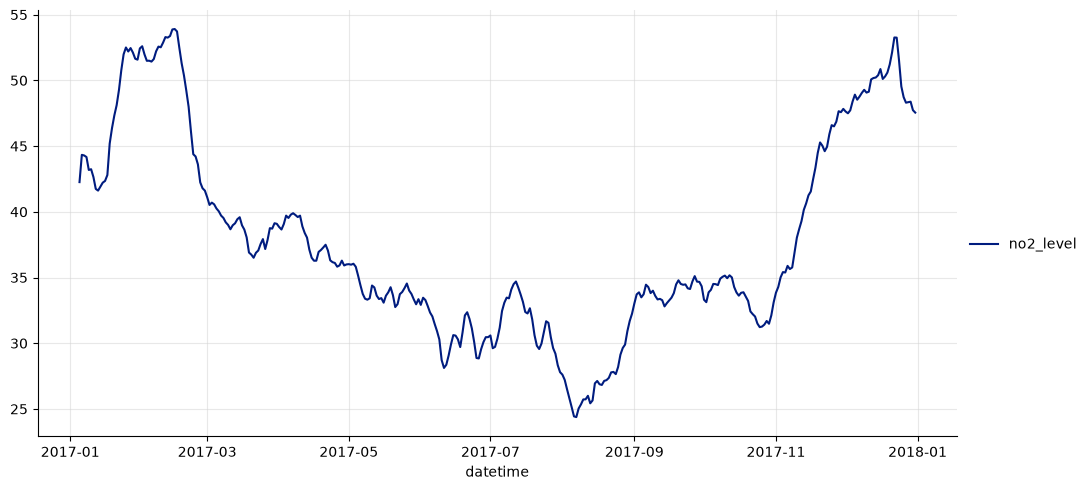

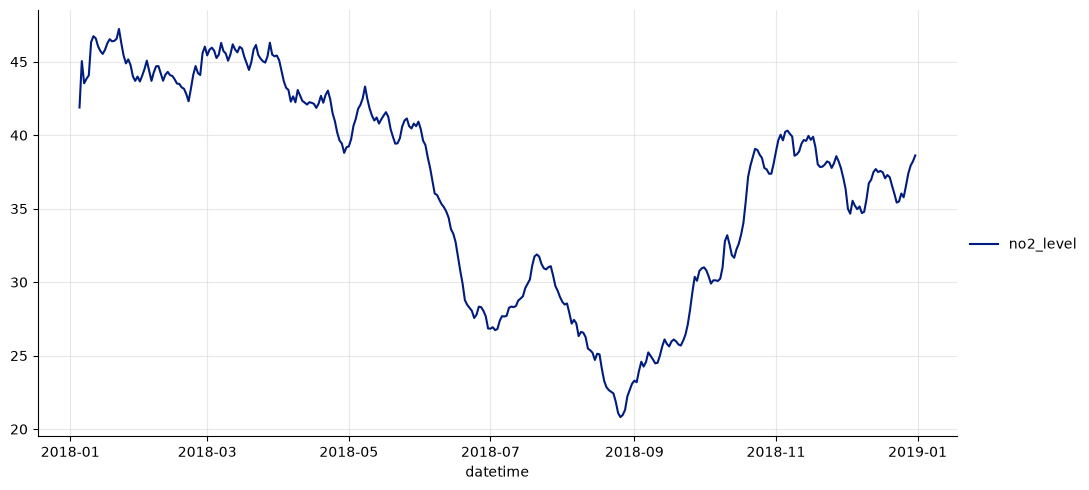

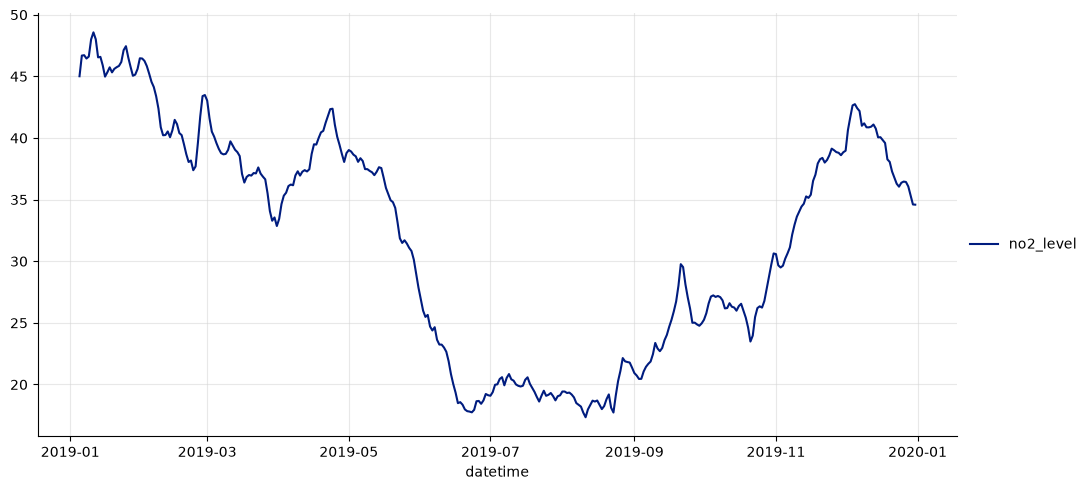

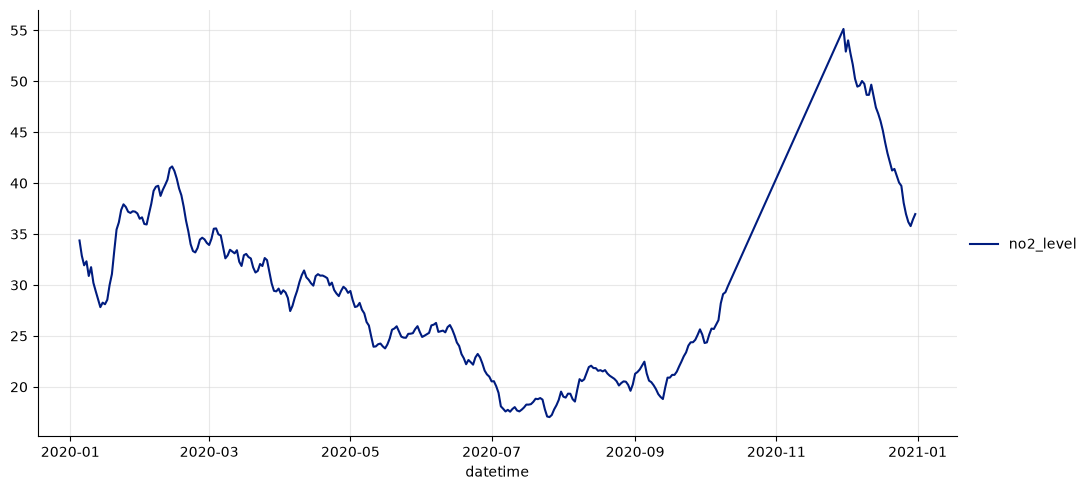

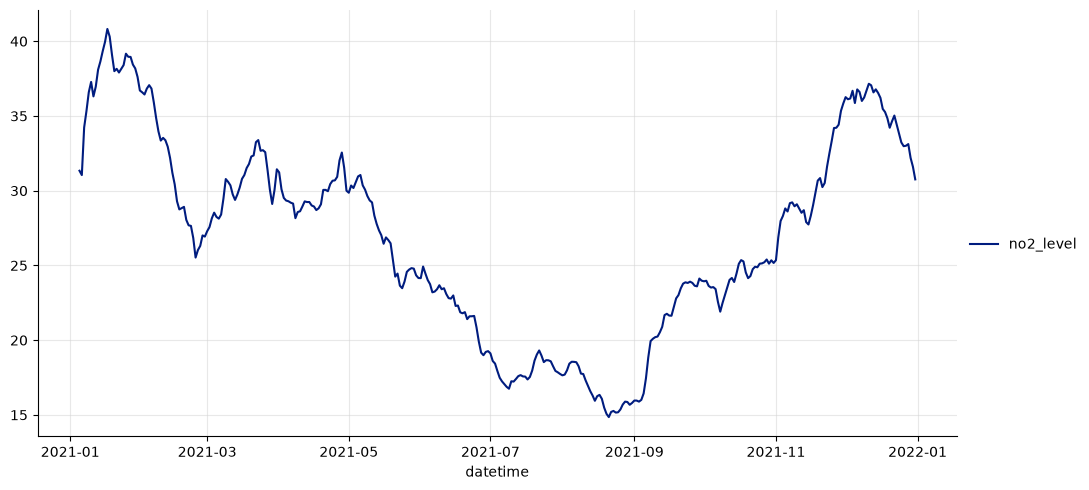

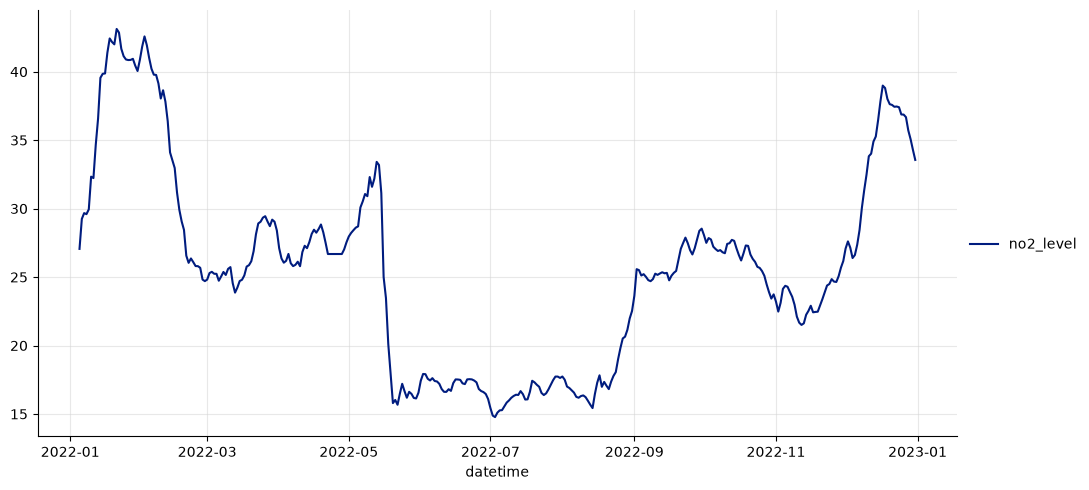

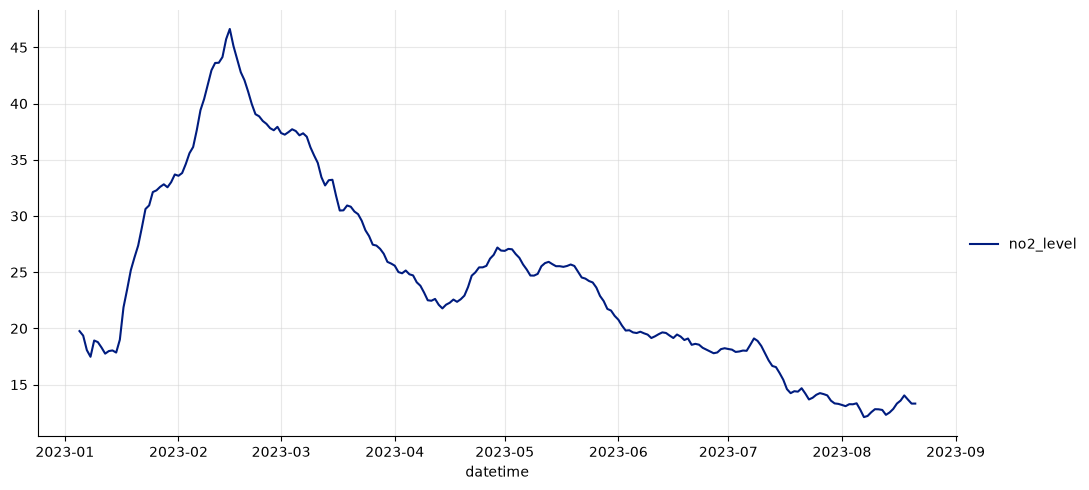

In [28]:
for year, year_df in data.groupby(data.index.year):

    year_df['no2_level'] = year_df['no2_level'].rolling(window=30, min_periods=5).mean()

    sns.relplot(year_df, kind="line", aspect=2)

We can see on these plots there is some ovbvious seasonality going on. summers are having much lower values then winters and we can also see a downwards moving trend in the complete dataset, we also had the covid pandemic which might have an influence over this. since there probably was less traffic during lockdown periods.

To keep enough data for forecasting and have an accurate view of data before and during the pandemic period, I choose to limit the scope of the data for forcasting from 2015 onwards, that gives me 3 years of pre covid data, and the rest of the during/post-covid.

I will limit the set and check what gaps in the data have to be solved here.

In [29]:
scope = data.loc["2015-01-01":, "no2_level"].to_frame()

In [30]:
scope.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 3155 entries, 2015-01-01 to 2023-08-21
Freq: D
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   no2_level  3031 non-null   float64
dtypes: float64(1)
memory usage: 49.3 KB


In [31]:
check_gaps(scope)

['2019-07-25 00:00:00 to 2019-07-29 00:00:00: 5 days',
 '2020-07-25 00:00:00 to 2020-07-26 00:00:00: 2 days',
 '2020-08-15 00:00:00 to 2020-08-17 00:00:00: 3 days',
 '2020-09-16 00:00:00 to 2020-09-29 00:00:00: 14 days',
 '2020-10-01 00:00:00 to 2020-11-25 00:00:00: 56 days',
 '2021-10-13 00:00:00 to 2021-10-14 00:00:00: 2 days',
 '2022-03-24 00:00:00 to 2022-03-29 00:00:00: 6 days',
 '2022-04-21 00:00:00 to 2022-05-15 00:00:00: 25 days',
 '2022-08-04 00:00:00 to 2022-08-14 00:00:00: 11 days']

I will check a few methods to impute the remaining missing periods. for 3 similar masked test lengths  I check how each method performs on the data of different years. afterwards I will use the most robust model to impute the missing values.

In [32]:
tests = {
    "5_day": {
        "2017": data.loc["2017-01-10":"2017-01-14", "no2_level"].copy(),
        "2018": data.loc["2018-01-10":"2018-01-14", "no2_level"].copy(),
        "2019": data.loc["2019-01-10":"2019-01-14", "no2_level"].copy(),
    },

    "14_day": {
        "2017": data.loc["2017-02-01":"2017-02-14", "no2_level"].copy(),
        "2018": data.loc["2018-02-01":"2018-02-14", "no2_level"].copy(),
        "2019": data.loc["2019-02-01":"2019-02-14", "no2_level"].copy(),
    },

    "25_day": {
        "2017": data.loc["2017-03-01":"2017-03-25", "no2_level"].copy(),
        "2018": data.loc["2018-03-01":"2018-03-25", "no2_level"].copy(),
        "2019": data.loc["2019-03-01":"2019-03-25", "no2_level"].copy(),
    },

    "56_day": {
        "2017": data.loc["2017-04-01":"2017-05-26", "no2_level"].copy(),
        "2018": data.loc["2018-04-01":"2018-05-26", "no2_level"].copy(),
        "2019": data.loc["2019-04-01":"2019-05-26", "no2_level"].copy(),
    }
}


small check if we have no Null values in the test periods:

In [33]:
for gap , years in tests.items():
    for year, test_period in years.items():

        previous = test_period.index - pd.DateOffset(years=1)
        print(gap, year, test_period.isna().sum(), previous.isna().sum())



5_day 2017 0 0
5_day 2018 0 0
5_day 2019 0 0
14_day 2017 0 0
14_day 2018 0 0
14_day 2019 0 0
25_day 2017 0 0
25_day 2018 0 0
25_day 2019 0 0
56_day 2017 0 0
56_day 2018 0 0
56_day 2019 0 0


Perfect, I am going to create a dataframe where I set these test periods to null values.

In [34]:

masked_data = scope.copy()


for gap , years in tests.items():
    for year, test_period in years.items():
        masked_data.loc[test_period.index, "no2_level"] = np.nan

next im going to create an evaluation pipeline. I will use the MAE (mean absolute error) and the MAPE (mean absolute percentage error) to evaluate the different methods. Below is the function for that.

In [35]:

def impute_evaluation(imputed_values: pd.DataFrame, tests: dict):

    results_MAE = {}
    results_MAPE = {}
    results_STD = {}

    for gap , years in tests.items():

        results_MAE.setdefault(gap, {})
        results_MAPE.setdefault(gap, {})
        results_STD.setdefault(gap, {})

        for year, test_period in years.items():

            predictions = imputed_values.loc[test_period.index, 'no2_level']


            if predictions.isna().sum() > 0:

                continue

            else:

                MAE = mean_absolute_error(test_period, predictions)
                results_MAE[gap][year] = MAE

                MAPE = mean_absolute_percentage_error(test_period, predictions)
                results_MAPE[gap][year] = MAPE

                std = test_period.std()
                results_STD[gap][year] = std


    MAE_df = round(pd.DataFrame(results_MAE).T.mean(axis=1),2)
    MAPE_df = round(pd.DataFrame(results_MAPE).T.mean(axis=1) * 100,2).astype(str) + '%'
    std_df = round(pd.DataFrame(results_STD).T.mean(axis=1),2)


    results = pd.concat([MAE_df, MAPE_df, std_df], axis=1, keys=['MAE', 'MAPE', 'std_real'])


    return results





I'm also going to create a function to plot my predicted values against the real values.

In [36]:
def plot_predictions(real_data, predictions, test, x_length: Literal["prediction", "2_months", "half_year", "full_year"] = "prediction" , ax= None):



    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 4))

    context = {
        "prediction": real_data.loc[
            test.index[0]:test.index[-1], "no2_level"
        ],
        "2_months": real_data.loc[
            test.index[0] - pd.DateOffset(months=2):test.index[-1], "no2_level"
        ],
        "half_year": real_data.loc[
            test.index[0] - pd.DateOffset(months=6):test.index[-1], "no2_level"
        ],
        "full_year": real_data.loc[
            test.index[0] - pd.DateOffset(years=1):test.index[-1], "no2_level"
        ]
    }

    test_window = predictions.loc[test.index]

    context[x_length].plot(
        ax=ax,
        color="midnightblue",
        label="actual"
    )

    test_window.plot(
        ax=ax,
        color="crimson",
        label="prediction"
    )

    ax.set_title(
        f"{test.index[0].date()} until {test.index[-1].date()}"
    )

    ax.legend()

    return ax



Im going to start with a basic time-series interpolation as a baseline

1. Time interpolation

In [37]:
interpolated = masked_data.interpolate(method="time")

In [38]:
impute_evaluation(interpolated, tests)

,MAE,MAPE,std_real
5_day,6.73,14.7%,9.54
14_day,14.85,46.04%,9.60
25_day,14.38,55.22%,10.94
56_day,11.50,29.95%,10.35


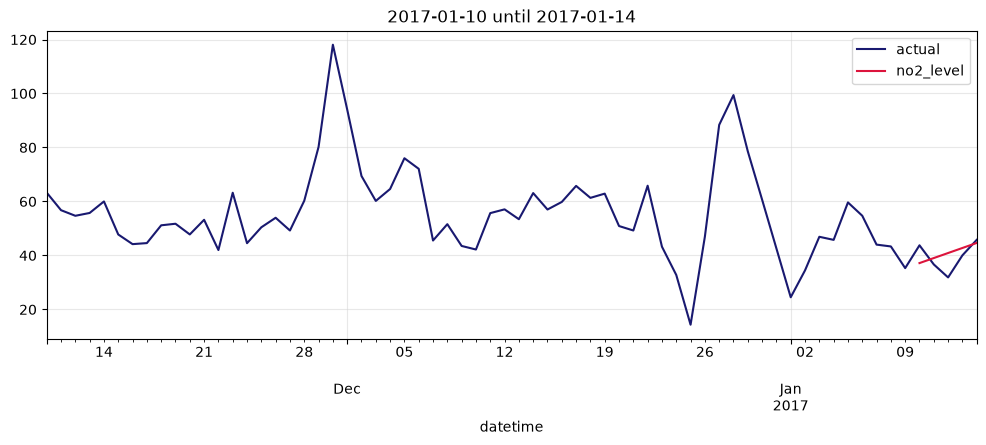

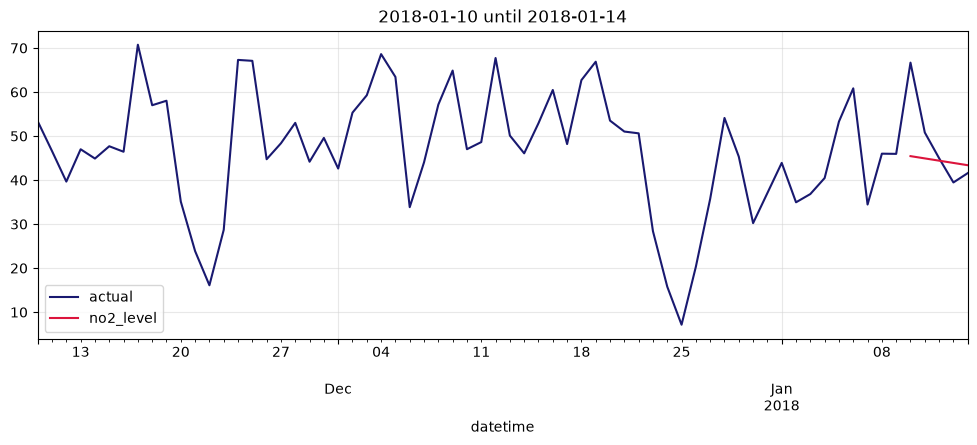

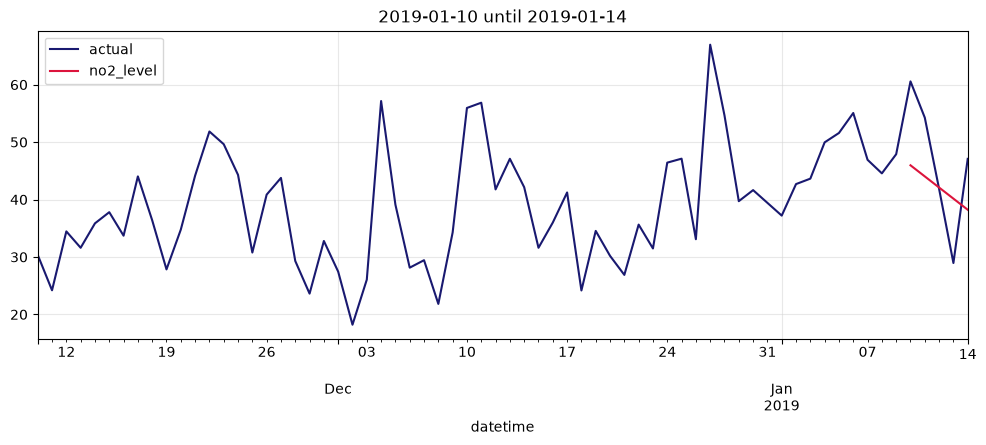

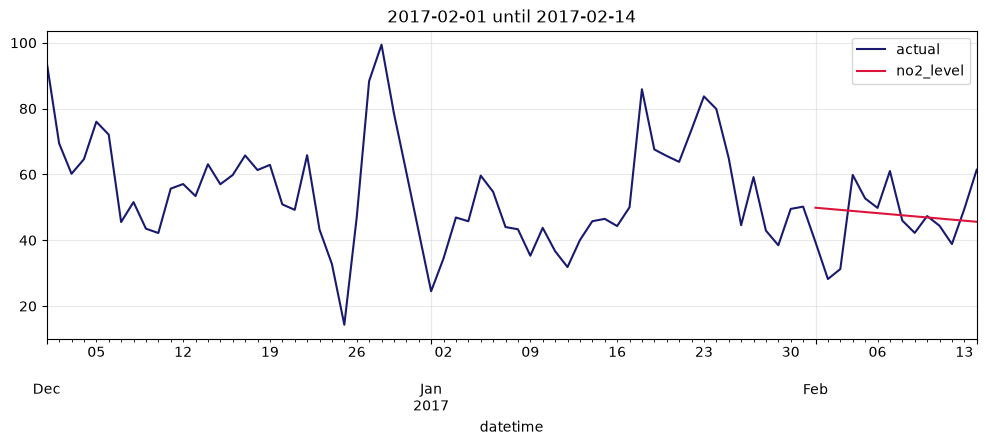

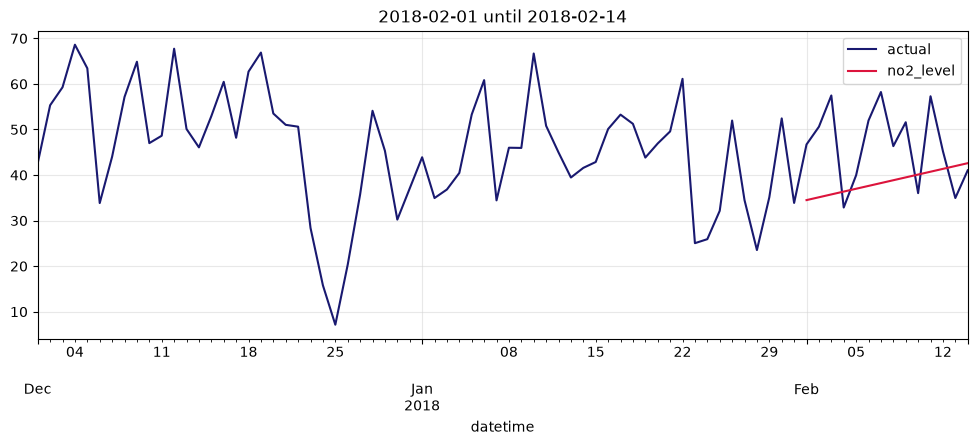

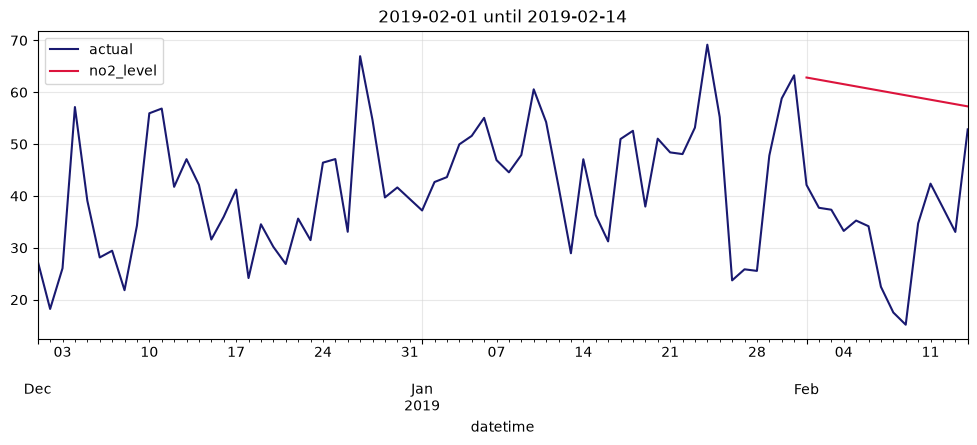

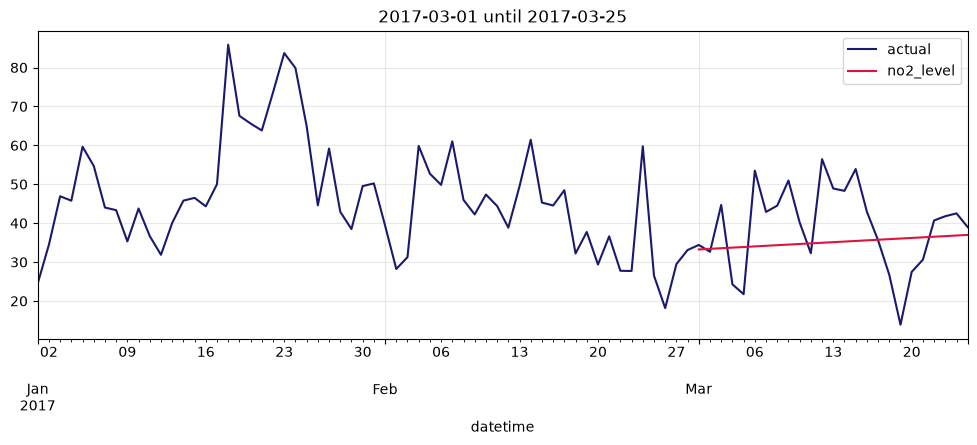

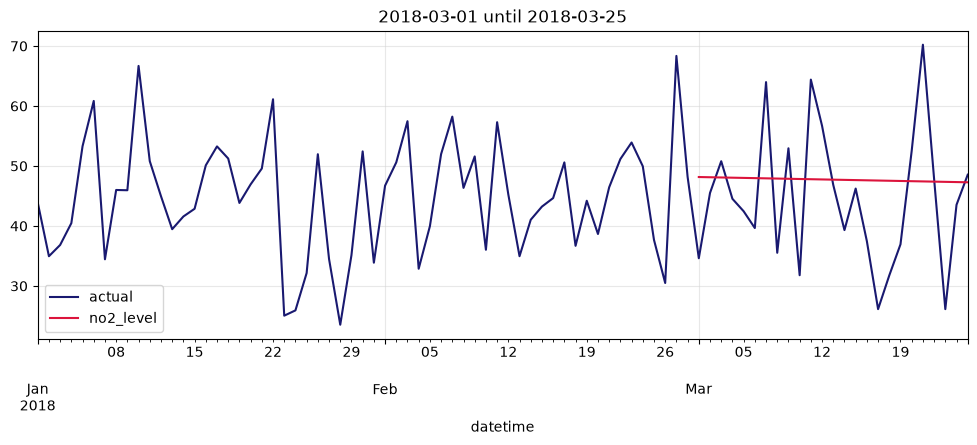

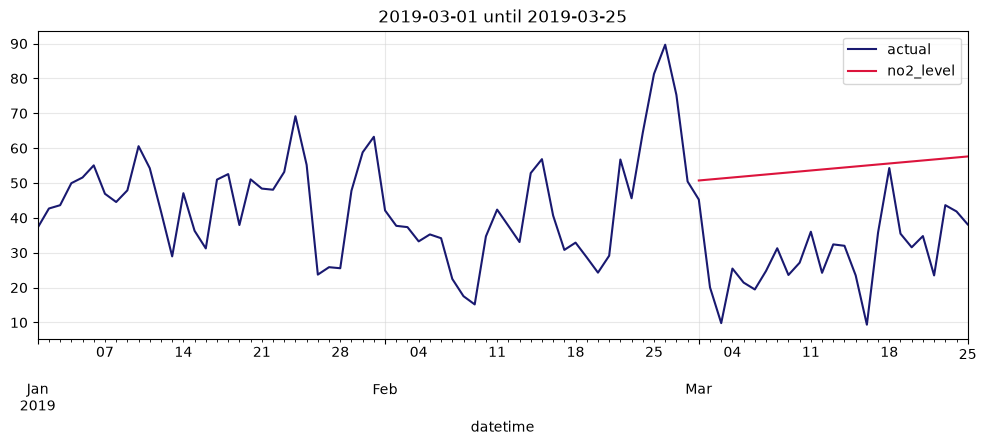

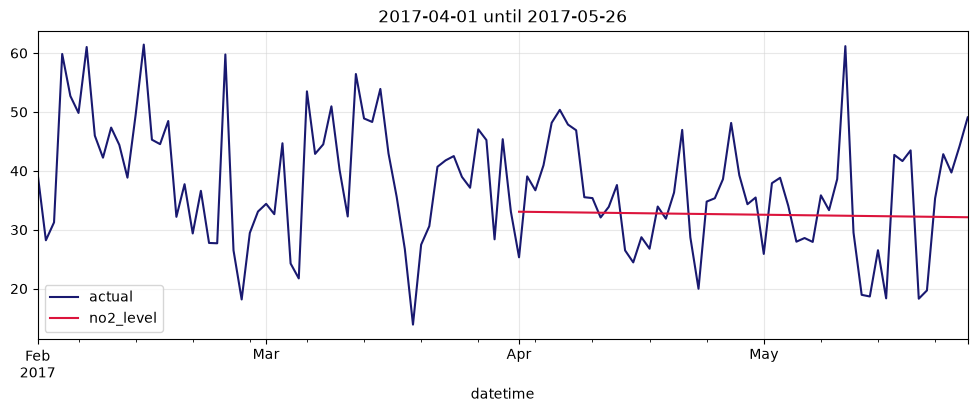

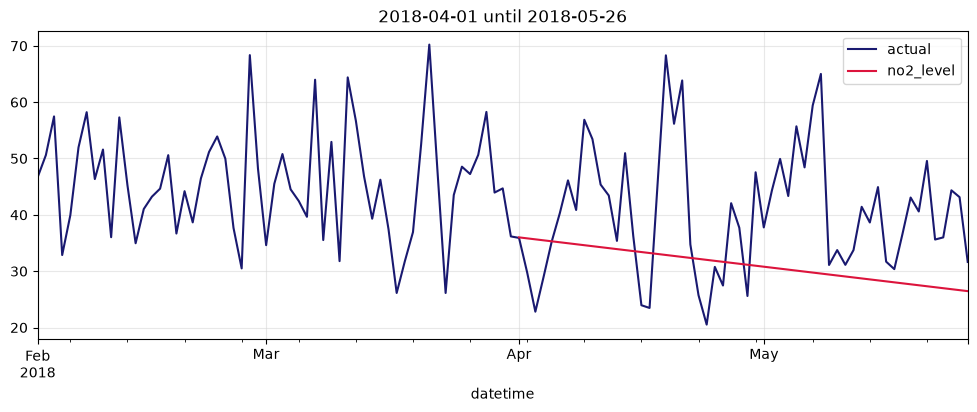

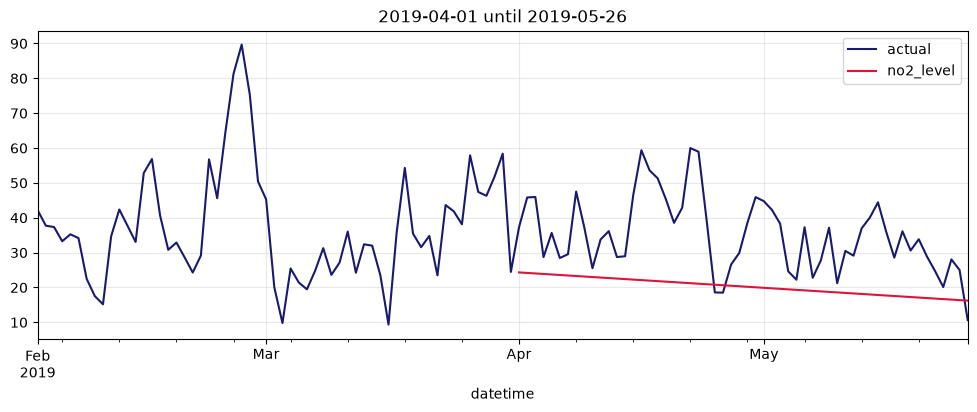

In [39]:
for gap , years in tests.items():
    for year, test_period in years.items():

        plot_predictions(scope, interpolated , test_period, x_length="2_months")

2. Seasonal Naive

In [40]:
def seasonal_naive(scope, tests):

    imputed = scope.copy()

    for gap, years in tests.items():
        for year, test_period in years.items():

            previous_year = test_period.index - pd.DateOffset(years=1)

            imputed.loc[test_period.index, "no2_level"] = (
                scope.loc[previous_year, "no2_level"].to_numpy()
            )

    return imputed


In [41]:
predictions = seasonal_naive(scope, tests)

In [42]:
impute_evaluation(predictions, tests)

,MAE,MAPE,std_real
5_day,11.86,28.28%,9.54
14_day,15.25,43.57%,9.60
25_day,16.59,59.08%,10.94
56_day,12.48,37.24%,10.35


3. Seasonal Naive but with a rolling 7 day mean window.

In [43]:
yearly_seasonal = masked_data.copy()

for gap , years in tests.items():
    for year, test_period in years.items():

        prev_year = test_period.index -  pd.DateOffset(years=1)

        yearly_seasonal.loc[test_period.index, 'no2_level'] =  scope.rolling(window=7, min_periods=1).mean().loc[prev_year, "no2_level"].to_numpy()

        comparison = pd.DataFrame({ 'original' : test_period,
                                    'imputed' : yearly_seasonal.loc[test_period.index, 'no2_level']})





In [44]:
impute_evaluation(yearly_seasonal, tests)

,MAE,MAPE,std_real
5_day,9.71,23.91%,9.54
14_day,9.40,29.3%,9.60
25_day,14.49,53.32%,10.94
56_day,9.99,31.58%,10.35


3. rolling mean (for short term gaps)

In [45]:
rolling_mean = masked_data.copy()

rolling_series = masked_data['no2_level'].rolling(window=7, min_periods=1).mean()

for gap , years in tests.items():
    for year, test_period in years.items():

        rolling_mean.loc[test_period.index, "no2_level"] = rolling_series.loc[test_period.index]


In [46]:
impute_evaluation(rolling_mean, tests)

,MAE,MAPE,std_real
5_day,7.12,17.01%,9.54
14_day,NaN,NaN,NaN
25_day,NaN,NaN,NaN
56_day,NaN,NaN,NaN


as we can see some methods perform better then others, but time interpolation looks best on short gaps here.

I would like to try SARIMA for the longer gaps but for that I need suffiecent training data without missing values. So I have decided I will use time interpolation for the smaller gaps equal and below 7 days as well.

In [47]:
missing = scope['no2_level'].isna()

gaps = missing.ne(missing.shift(1)).cumsum()
gap_size = missing.groupby(gaps).transform('sum')

mask = missing & (gap_size <= 7)

In [48]:
scope.loc[mask, "no2_level"] = scope.interpolate(method="time").loc[mask, "no2_level"]

In [49]:
check_gaps(scope)

['2020-09-16 00:00:00 to 2020-09-29 00:00:00: 14 days',
 '2020-10-01 00:00:00 to 2020-11-25 00:00:00: 56 days',
 '2022-04-21 00:00:00 to 2022-05-15 00:00:00: 25 days',
 '2022-08-04 00:00:00 to 2022-08-14 00:00:00: 11 days']

We have 3 bigger gaps left now, and no missing values before 2020-09-16.

Now I can proceed and look if using forecasting models would be robust for filling these gaps.
 I will create similar test periods as the real missing data, so that we have a similar seasonality, I will then use all the data before this period to train the ARIMA / SARIMA model and evaluate the performance against the real data.

In [50]:
arima_tests = {
    "14_day": {
        "2017": scope.loc["2017-09-16":"2017-09-29", "no2_level"].copy(),
        "2018": scope.loc["2018-09-16":"2018-09-29", "no2_level"].copy(),
        "2019": scope.loc["2019-09-16":"2019-09-29", "no2_level"].copy(),
    },

    "56_day": {
        "2017": scope.loc["2017-10-01":"2017-11-25", "no2_level"].copy(),
        "2018": scope.loc["2018-10-01":"2018-11-25", "no2_level"].copy(),
        "2019": scope.loc["2019-10-01":"2019-11-25", "no2_level"].copy(),
    },

    "25_day": {
        "2017": scope.loc["2017-04-21":"2017-05-15", "no2_level"].copy(),
        "2018": scope.loc["2018-04-21":"2018-05-15", "no2_level"].copy(),
        "2019": scope.loc["2019-04-21":"2019-05-15", "no2_level"].copy(),
    }
}



In [51]:
pred = seasonal_naive(scope, arima_tests)

In [52]:
impute_evaluation(pred, arima_tests)

,MAE,MAPE,std_real
14_day,15.98,75.77%,12.89
56_day,12.54,42.4%,11.93
25_day,13.12,39.85%,10.89


mask test sets

In [53]:
arima_masked = scope.copy()

for gap, years in arima_tests.items():
    for year, test_period in years.items():

        arima_masked.loc[test_period.index, "no2_level"] = np.nan




splitting training data before the first occuring test

In [54]:

end_of_train=  arima_tests["14_day"]["2017"].index[0] - pd.Timedelta(days=1)
train = scope[:end_of_train]


checking for any missing values in the training set to be sure

In [55]:
check_gaps(train)

There are no missing values in the set


Now i will check ACF and PACF on the selected training data.

In [56]:
def plot_acf_pacf(series, lags=100):

    fig, axes = plt.subplots(2,1, figsize=(10,10))


    plot_acf(series, ax=axes[0], lags=lags)

    plot_pacf(series, ax=axes[1],lags=lags)

    for ax in axes:
        ax.set_xticks(np.arange(0,lags ,5))
        ax.grid(True, color='grey', linewidth=0.3, linestyle='--', axis="x")


    axes[0].set_title("ACF")
    axes[1].set_title("PACF")


    plt.show()

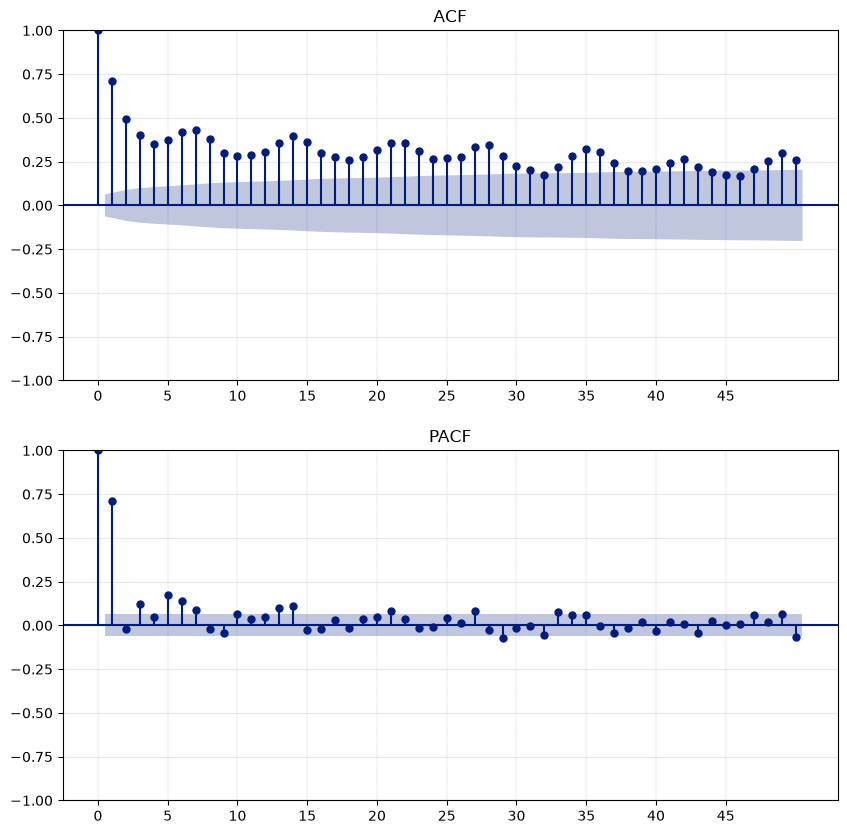

In [57]:
df_series = train["no2_level"]
plot_acf_pacf(df_series, lags=50)

We can clearly conclude from the above ACF plot that the data is non-stationary and we can also get a glimpse of some seasonality going on in there, due to the sinus shape of the ACF plot. I will difference the values and take a look again.

In [58]:
scope["no2_diff"] = scope["no2_level"].diff()

train_diff = scope.loc[:end_of_train, "no2_diff"]
train_diff = train_diff.dropna()

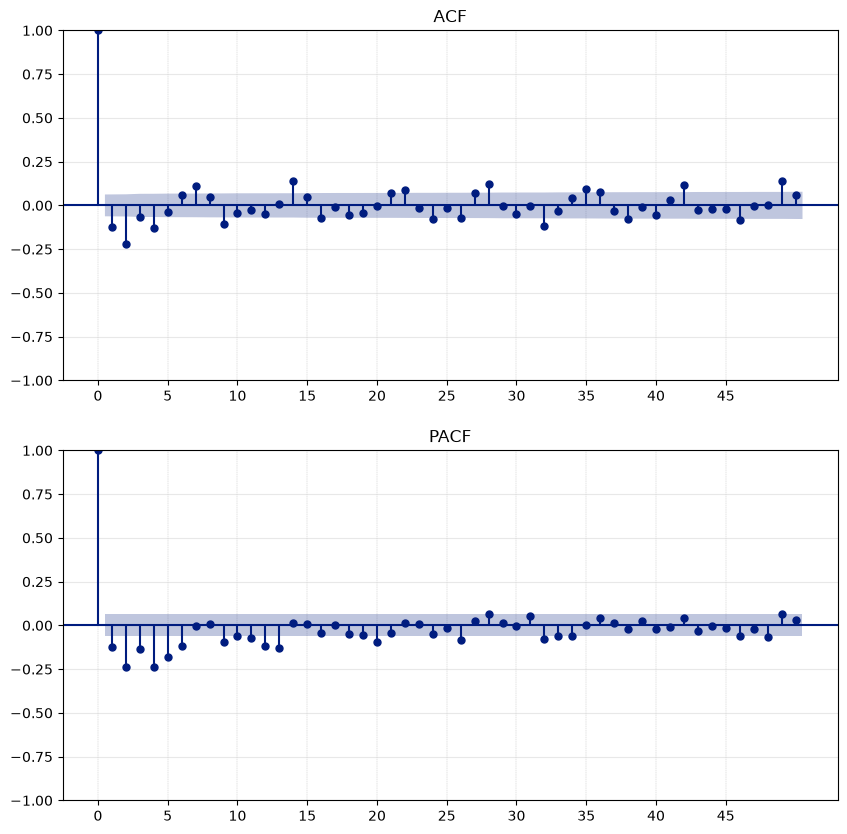

In [59]:
plot_acf_pacf(train_diff, 50)

We still have a 7 days seasonal trend in the ACF plot. Im going to check what an extra seasonal differencing produces.

In [60]:
scope["no2_seasoned_diff"] = scope["no2_diff"].diff(periods=7)

train_diff = scope.loc[:end_of_train, "no2_seasoned_diff"]
train_diff = train_diff.dropna()

In [61]:
    train_diff.info()

<class 'pandas.Series'>
DatetimeIndex: 981 entries, 2015-01-09 to 2017-09-15
Freq: D
Series name: no2_seasoned_diff
Non-Null Count  Dtype  
--------------  -----  
981 non-null    float64
dtypes: float64(1)
memory usage: 15.3 KB


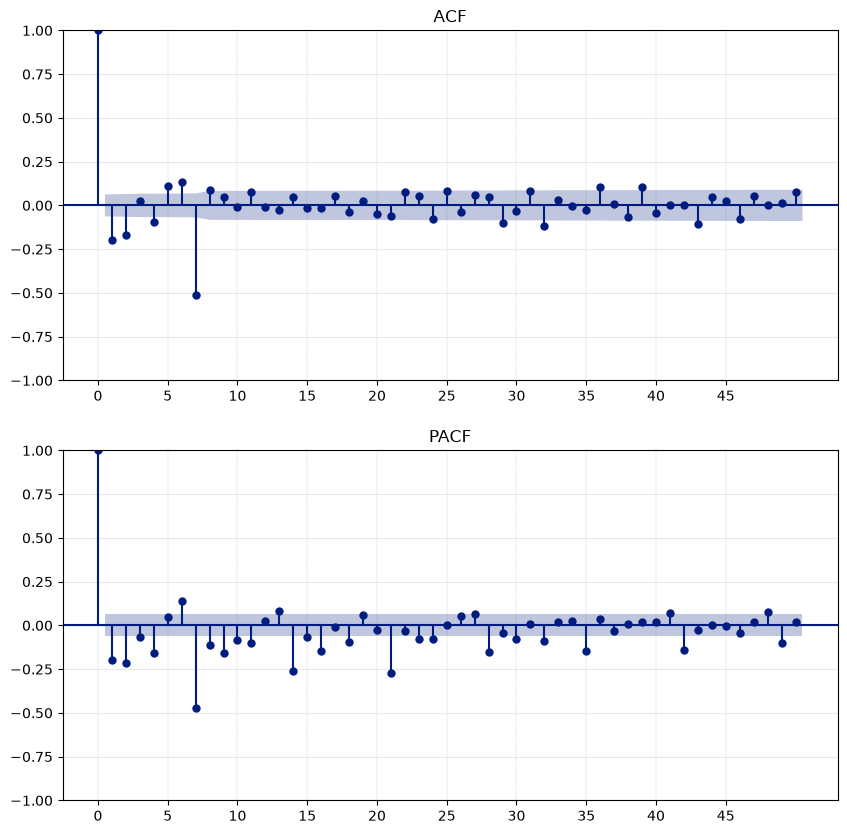

In [62]:
plot_acf_pacf(train_diff, 50)

Based on these plots, D=1 creates a strong negative spike at lag 7, which might indicate D=1, I will include both D=0 and D=1 in testing.

I will reset the seasonal differencing and use this insight for model selection.

In [63]:
scope = scope.drop(columns=["no2_seasoned_diff"])
train_diff = scope.loc[:end_of_train, "no2_diff"].dropna()



In the earlier plotting of the rolling mean across the different years, we can see a yearly pattern as wel. I will try to account for this with fourier terms. I will try to find the optimal K and incorporate the yearly seasonality through exogenous terms.

In [64]:
def create_fourier(time_data, K, period):

    """Creates Fourier terms for the complete scope of the project (historic + potential
        forecasting dates if added to time_data, based on the number of harmonics
        (K) and the seasonal period."""

    t = np.arange(len(time_data))
    fourier_terms = pd.DataFrame(index=time_data.index)

    for k in range(1, K + 1):
        fourier_terms[f"sin_{k}"] = np.sin(2 * np.pi * k * t / period)
        fourier_terms[f"cos_{k}"] = np.cos(2 * np.pi * k * t / period)

    return fourier_terms


In [65]:
 def find_best_K_fourier(scope, train):

    """Finds the best number of Fourier terms (K) by selecting the result with the lowestAIC."""

    results = {"fourier_k": [],
               "aic": []}

    for K in range(0,5):

        fourier_terms = create_fourier(scope, K, period= 365.25)
        # order and seasonal order are dummy
        model = SARIMAX(train, exog=fourier_terms.loc[train.index], order=(1,1,1), seasonal_order=(1,1,1,7))
        fitted = model.fit()
        aic = fitted.aic

        results["fourier_k"].append(K)
        results["aic"].append(aic)

    df = pd.DataFrame(results)

    best_K = df.loc[df["aic"].idxmin(), "fourier_k"]

    return best_K


In [66]:
find_best_K_fourier(scope,train)

/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = s

np.int64(1)

with the optimal K at 1, I can create the fourier_terms that I will use in the model

In [67]:
exog = create_fourier(scope, 1, period= 365.25)

In [68]:
print(exog)

               sin_1     cos_1
datetime                      
2015-01-01  0.000000  1.000000
2015-01-02  0.017202  0.999852
2015-01-03  0.034398  0.999408
2015-01-04  0.051584  0.998669
2015-01-05  0.068755  0.997634
...              ...       ...
2023-08-17 -0.703677 -0.710520
2023-08-18 -0.715795 -0.698310
2023-08-19 -0.727701 -0.685894
2023-08-20 -0.739392 -0.673275
2023-08-21 -0.750864 -0.660457

[3155 rows x 2 columns]


I can extract candidates for p and q values from the first order differenced plot, for the p value I will start with values up until 6, and let the seasonal hyperparameters handle from the 7th lag on the above seasonal differenced plot

In [69]:
def grid_search_parameters(pdq, seasonal_pdq, train, exog):

    resultsGS = {
        "pdq": [],
        "seasonal_pdq": [],
        "AIC": []}


    for combo in pdq:
        for s_combo in seasonal_pdq:

            try:
                model = SARIMAX(train, exog=exog.loc[train.index], order=combo, seasonal_order=s_combo)
                fitted = model.fit(disp=False)
                aic = fitted.aic

                resultsGS['pdq'].append(combo)
                resultsGS['seasonal_pdq'].append(s_combo)
                resultsGS['AIC'].append(aic)

            except Exception as Error:
                print(Error)
                continue

    print("Grid search finished")

    return resultsGS


In [70]:
p = range(0,3)
d = [1]
q = range(0,3)

# seasonal

P = range(0,3)
D = [0,1]
Q = [0,1]
s = [7]

# Combinations

pdq = list(itertools.product(p,d,q))
seasonal_pdq= list(itertools.product(P,D,Q,s))

resultsGS = grid_search_parameters(pdq, seasonal_pdq, train, exog)


/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = s

Grid search finished


/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [71]:
def create_selection(resultsGS, amount: int = 3):

    results_df = pd.DataFrame(resultsGS)
    results_df.sort_values("AIC", inplace=True)
    results_df.reset_index(inplace=True)



    top = results_df.head(amount)

    return top



In [72]:
top = create_selection(resultsGS, amount=3)

In [73]:
print(top)

   index        pdq  seasonal_pdq          AIC
0     99  (2, 1, 2)  (0, 1, 1, 7)  7448.188139
1     63  (1, 1, 2)  (0, 1, 1, 7)  7450.070852
2     87  (2, 1, 1)  (0, 1, 1, 7)  7450.658202


it looks like our grid search has returned pdq(2, 1, 2)	seasonal_pdq(0, 1, 1, 7) as the best result.
To get a bit bigger validation comparison, I will test the models with best AIC scores.
I will create an evaluation pipeline capable of testing forecasting and imputation with kalman smoothing.

In [74]:
def run_SARIMAX_forecast(pdq: tuple, s_pdq: tuple, train_df, test_period, exog) -> pd.DataFrame:
    """Function that takes model hyperparameters and train and test window + Exogenous features+
    limits training data."""

    end_of_train = test_period.index[0] - pd.Timedelta(days=1)
    train = train_df.loc[:end_of_train, "no2_level"].copy()

    # train & fit


    model = SARIMAX(train, order=pdq, seasonal_order=s_pdq,
                    exog=exog[:end_of_train] if exog is not None else None)
    fitted = model.fit(disp=False)

    predictions = fitted.get_forecast(steps=len(test_period), exog=exog.loc[test_period.index[0]:end_of_train + pd.Timedelta(days=14)] if exog is not None else None)
    predictions = predictions.summary_frame(alpha=0.05)

    return predictions



In [75]:

def eval_model(models: pd.DataFrame,
               train_df: pd.DataFrame,
               test_dict: dict,
               train_selection: Literal["impute", "forecast"] = 'forecast',
               exog: pd.DataFrame = None) -> tuple:

    results = []

    prediction_values = []



    for _ , row in models.iterrows() :

        for gap, years in test_dict.items():

            gap_score_MAE= []
            gap_score_RMSE = []
            gap_score_MAPE = []

            for year, test_period in years.items():

                if train_selection == "forecast":

                    predictions = run_SARIMAX_forecast(row["pdq"], row["seasonal_pdq"], train_df, test_period, exog)


                elif train_selection == "impute":

                    # full data with test period gap
                    fold = train_df["no2_level"].copy()

                    fold.loc[test_period.index] = np.nan

                    model = SARIMAX(fold, order=row["pdq"], seasonal_order=row["seasonal_pdq"],
                                    exog=exog if exog is not None else None)
                    fitted = model.fit(disp=False)

                    predictions = fitted.get_prediction(start=test_period.index[0],
                                                         end=test_period.index[-1],
                                                         information_set= "smoothed")

                    predictions = predictions.summary_frame(alpha=0.05)

                for date in predictions.index:

                        prediction_values.append({
                            "pdq": row["pdq"],
                            "seasonal_pdq": row["seasonal_pdq"],
                            "gap": gap,
                            "year": year,
                            "date": date,
                            "prediction": predictions.loc[date, 'mean'],
                            "actual": test_period.loc[date]

                        })
                # calculate metrics

                MAE = mean_absolute_error(test_period, predictions['mean'])
                RMSE = root_mean_squared_error(test_period, predictions['mean'])
                MAPE = mean_absolute_percentage_error(test_period, predictions['mean'])

                gap_score_MAE.append(MAE)
                gap_score_RMSE.append(RMSE)
                gap_score_MAPE.append(MAPE)

            mean_mae = np.mean(gap_score_MAE)
            mean_rmse = np.mean(gap_score_RMSE)
            mean_mape = np.mean(gap_score_MAPE)


            # Extract results to df for plotting

            results.append({
                        "pdq": row["pdq"],
                        "seasonal_pdq": row["seasonal_pdq"],
                        "gap": gap,
                        "MAE": mean_mae,
                        "RMSE": mean_rmse,
                        "MAPE": mean_mape,
                    })

    results_df = pd.DataFrame(results)
    predictions_df = pd.DataFrame(prediction_values)

    results_df.sort_values(["MAE"], inplace=True)

    return results_df, predictions_df








In [76]:
results_df, predictions_df = eval_model(top, scope, arima_tests, "impute", exog)


/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = s

check for lowest RSME per gap, inspecting the models performance

In [77]:
predictions_df = predictions_df.set_index('date')

In [78]:
results_df.sort_values(["gap", "RMSE"], inplace=True)

In [79]:
results_df

,pdq,seasonal_pdq,gap,MAE,RMSE,MAPE
6,"(2, 1, 1)","(0, 1, 1, 7)",14_day,10.017256,11.923212,0.422828
0,"(2, 1, 2)","(0, 1, 1, 7)",14_day,10.028591,11.931573,0.421603
3,"(1, 1, 2)","(0, 1, 1, 7)",14_day,10.028724,11.937835,0.423431
8,"(2, 1, 1)","(0, 1, 1, 7)",25_day,8.660714,10.961686,0.235165
5,"(1, 1, 2)","(0, 1, 1, 7)",25_day,8.666579,10.965743,0.235338
2,"(2, 1, 2)","(0, 1, 1, 7)",25_day,8.688711,10.980633,0.237074
1,"(2, 1, 2)","(0, 1, 1, 7)",56_day,8.806664,11.063313,0.294116
4,"(1, 1, 2)","(0, 1, 1, 7)",56_day,8.752545,11.067698,0.290172
7,"(2, 1, 1)","(0, 1, 1, 7)",56_day,8.755977,11.070594,0.290299


Seasonal P,D,Q looks the same across across the board

In [80]:
print(predictions_df)

                  pdq  seasonal_pdq     gap  year  prediction     actual
date                                                                    
2017-09-16  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   35.328804  36.579167
2017-09-17  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   30.070335  31.175000
2017-09-18  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   35.062639  41.578261
2017-09-19  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   36.736370  40.483333
2017-09-20  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   37.115431  34.166667
...               ...           ...     ...   ...         ...        ...
2019-05-11  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   25.442330  30.500000
2019-05-12  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   21.784499  29.120833
2019-05-13  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   27.979489  36.973913
2019-05-14  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   30.949850  40.045833
2019-05-15  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   33.410220  44.429167

[855 rows x 6 columns]


selecting first potential model

In [81]:
mask = (predictions_df['pdq'] == results_df.iloc[0,0]) & (predictions_df['seasonal_pdq'] == (0,1,1,7))

In [82]:
model = predictions_df.loc[mask]

compare model to test set.

In [83]:
print(mask)

date
2017-09-16    False
2017-09-17    False
2017-09-18    False
2017-09-19    False
2017-09-20    False
              ...  
2019-05-11     True
2019-05-12     True
2019-05-13     True
2019-05-14     True
2019-05-15     True
Length: 855, dtype: bool


In [84]:
print(plt.style.available)
plt.style.use('ggplot')

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


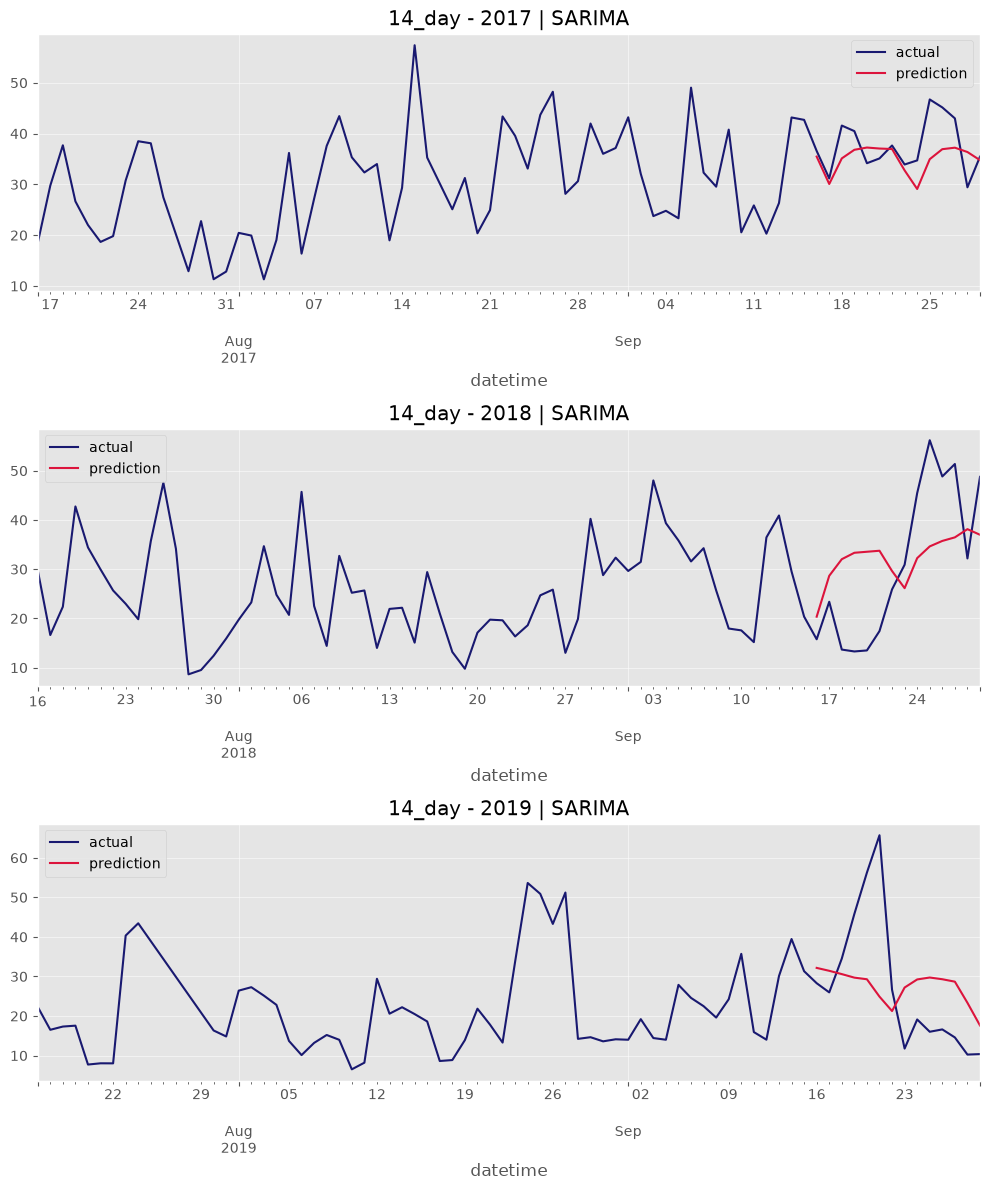

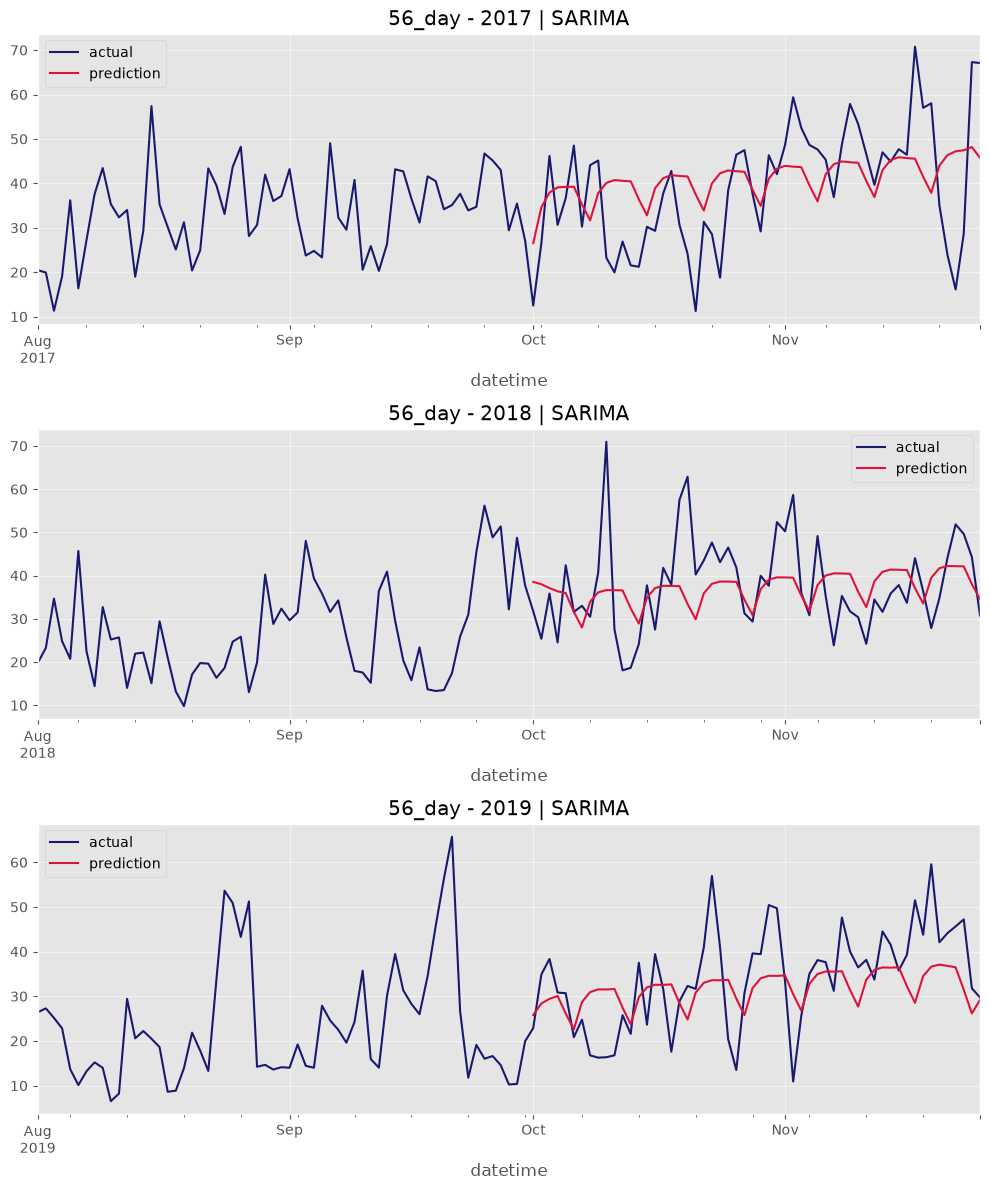

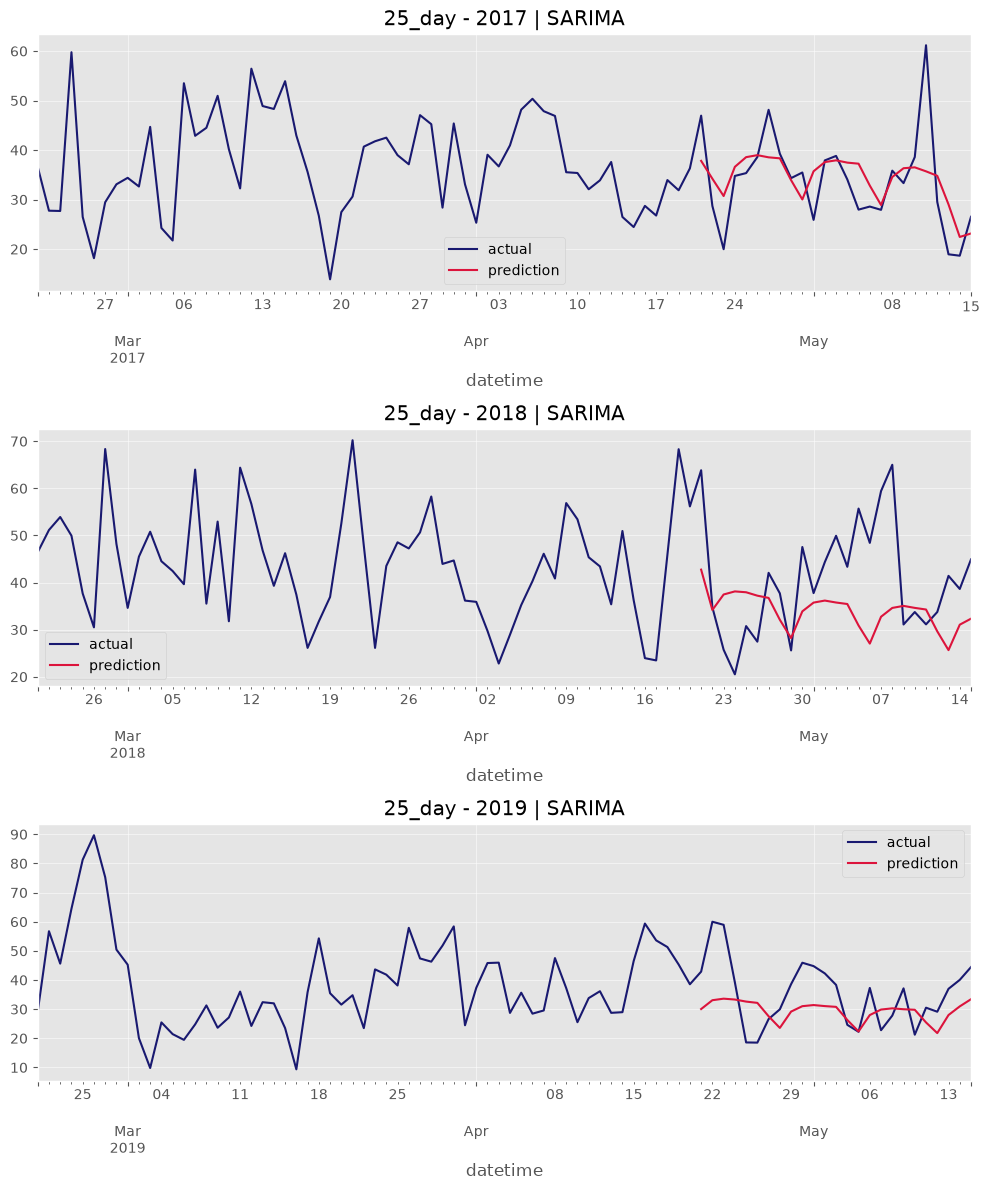

In [85]:
for gap, years in arima_tests.items():

    fig, axes = plt.subplots(
        len(years), 1,
        figsize=(10, 4 * len(years))
    )

    for ax, (year, test_period) in zip(axes, years.items()):

        plot_predictions(
            scope,
            model["prediction"],
            test_period,
            x_length="2_months",
            ax=ax
        )

        ax.set_title(f"{gap} - {year} | SARIMA")

    plt.tight_layout()
    plt.show()

# Including Weather API

The models seems to follow the seasonality pretty well, Although this data has a lot of noise currently that has an effect on the variance. I'm speculating that no2_levels are probably somewhat dependent on the weather. Im going to include historic and forecasted weather data to try and improve the forecast with open-meteo API data.

In [86]:

start_date = "2010-01-01"
end_date =  "2023-08-21"


def call_historic_weather(lat, long, start_date, end_date):

    # Setup the Open-Meteo API client with cache and retry on error
    cache_session = requests_cache.CachedSession('.cache', expire_after = 3600)
    retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
    openmeteo = openmeteo_requests.Client(session = retry_session)

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": lat,
        "longitude": long,
        "start_date": start_date,
        "end_date": end_date,
        "daily": ["temperature_2m_max", "temperature_2m_min", "wind_speed_10m_max", "precipitation_sum"],
    }
    responses = openmeteo.weather_api(url, params = params)

    # Process first location.
    response = responses[0]
    print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
    print(f"Elevation: {response.Elevation()} m asl")
    print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

    # Process daily data. The order of variables needs to be the same as requested.
    daily = response.Daily()
    daily_temperature_2m_max = daily.Variables(0).ValuesAsNumpy()
    daily_temperature_2m_min = daily.Variables(1).ValuesAsNumpy()
    daily_wind_speed_10m_max = daily.Variables(2).ValuesAsNumpy()
    daily_precipitation_sum = daily.Variables(3).ValuesAsNumpy()

    daily_data = {"date": pd.date_range(
        start=pd.to_datetime(daily.Time(), unit="s", ),
        end=pd.to_datetime(daily.TimeEnd(), unit="s",),
        freq=pd.Timedelta(seconds=daily.Interval()),
        inclusive="left"
    ), "temperature_2m_max": daily_temperature_2m_max, "temperature_2m_min": daily_temperature_2m_min,
        "wind_speed_10m_max": daily_wind_speed_10m_max, "precipitation_sum": daily_precipitation_sum}

    daily_dataframe = pd.DataFrame(data = daily_data).set_index("date").sort_index()
    print("\nDaily data\n", daily_dataframe)

    return daily_dataframe

Use the location coordinates I have extracted from the original data, and give them to the API

In [87]:
daily_data = call_historic_weather(location[0], location[1], start_date, end_date)

Coordinates: 51.49384689331055°N -0.16302490234375°E
Elevation: 33.0 m asl
Timezone difference to GMT+0: 0s

Daily data
             temperature_2m_max  temperature_2m_min  wind_speed_10m_max  \
date                                                                     
2010-01-01            2.156399           -2.650958           18.331741   
2010-01-02            3.338039           -1.044252           16.071491   
2010-01-03            1.959638           -4.265000           13.755579   
2010-01-04            1.118546           -5.465054           10.823973   
2010-01-05            1.535000           -4.371140           15.646544   
...                        ...                 ...                 ...   
2023-08-17           22.963776           14.845737           23.444265   
2023-08-18           24.775928           16.049999           22.331610   
2023-08-19           23.300234           15.200000           27.776047   
2023-08-20           24.053125           14.842376           19.0

In [88]:
def add_to_exog(exog, daily_data):

    """Adds the weather data to the exog dataframe"""

    exog = exog.join(daily_data, how= "left")

    return  exog

Add the extracted dates to the exogenous features,

In [89]:
exog = add_to_exog(exog, daily_data)

In [90]:
def limit_exog_to_weather_data(train, exog, days):

    start = train.index[0]
    end = train.index[-1] + pd.Timedelta(days=days)

    exog_cut = exog.loc[start:end].copy()

    return exog_cut

# SARIMAX with Weatherdata + fourier exog

run gridsearch with all features.

In [91]:
resultsGS = grid_search_parameters(pdq, seasonal_pdq, train, exog)



/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = s

Grid search finished


/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


extract the top 3 models ranked by AIC

In [92]:
top = create_selection(resultsGS, 1 )

Run the evaluation pipeline for the top 3 models

In [93]:
results_df, weather_predictions_df = eval_model(top, scope, arima_tests, "impute", exog)

/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = s

In [94]:
results_df

,pdq,seasonal_pdq,gap,MAE,RMSE,MAPE
1,"(0, 1, 2)","(0, 1, 1, 7)",56_day,5.561743,7.078107,0.169355
0,"(0, 1, 2)","(0, 1, 1, 7)",14_day,5.898932,7.927759,0.193231
2,"(0, 1, 2)","(0, 1, 1, 7)",25_day,6.710284,8.772033,0.190116


plot a promising model

In [95]:
best_pdq: tuple = results_df.iloc[0,0]
best_s_pdq : tuple = results_df.iloc[0,1]

In [96]:
weather_predictions_df.index

RangeIndex(start=0, stop=285, step=1)

In [97]:
weather_predictions_df = weather_predictions_df.set_index('date')

In [98]:
print(model)

                  pdq  seasonal_pdq     gap  year  prediction     actual
date                                                                    
2017-09-16  (2, 1, 1)  (0, 1, 1, 7)  14_day  2017   35.473363  36.579167
2017-09-17  (2, 1, 1)  (0, 1, 1, 7)  14_day  2017   30.075130  31.175000
2017-09-18  (2, 1, 1)  (0, 1, 1, 7)  14_day  2017   35.115136  41.578261
2017-09-19  (2, 1, 1)  (0, 1, 1, 7)  14_day  2017   36.807869  40.483333
2017-09-20  (2, 1, 1)  (0, 1, 1, 7)  14_day  2017   37.253456  34.166667
...               ...           ...     ...   ...         ...        ...
2019-05-11  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   25.442330  30.500000
2019-05-12  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   21.784499  29.120833
2019-05-13  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   27.979489  36.973913
2019-05-14  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   30.949850  40.045833
2019-05-15  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   33.410220  44.429167

[285 rows x 6 columns]


In [99]:
print(predictions_df)

                  pdq  seasonal_pdq     gap  year  prediction     actual
date                                                                    
2017-09-16  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   35.328804  36.579167
2017-09-17  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   30.070335  31.175000
2017-09-18  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   35.062639  41.578261
2017-09-19  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   36.736370  40.483333
2017-09-20  (2, 1, 2)  (0, 1, 1, 7)  14_day  2017   37.115431  34.166667
...               ...           ...     ...   ...         ...        ...
2019-05-11  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   25.442330  30.500000
2019-05-12  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   21.784499  29.120833
2019-05-13  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   27.979489  36.973913
2019-05-14  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   30.949850  40.045833
2019-05-15  (2, 1, 1)  (0, 1, 1, 7)  25_day  2019   33.410220  44.429167

[855 rows x 6 columns]


In [100]:
print(weather_predictions_df)
print(mask)
print(best_pdq)
print(best_s_pdq)

                  pdq  seasonal_pdq     gap  year  prediction     actual
date                                                                    
2017-09-16  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   38.898682  36.579167
2017-09-17  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   37.346157  31.175000
2017-09-18  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   37.810220  41.578261
2017-09-19  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   45.318198  40.483333
2017-09-20  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   39.183922  34.166667
...               ...           ...     ...   ...         ...        ...
2019-05-11  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   27.601777  30.500000
2019-05-12  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   29.637975  29.120833
2019-05-13  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   33.371251  36.973913
2019-05-14  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   31.609065  40.045833
2019-05-15  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   38.136432  44.429167

[285 rows x 6 columns]
date
2017-09-16    False
20

In [101]:
print(weather_predictions_df)

                  pdq  seasonal_pdq     gap  year  prediction     actual
date                                                                    
2017-09-16  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   38.898682  36.579167
2017-09-17  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   37.346157  31.175000
2017-09-18  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   37.810220  41.578261
2017-09-19  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   45.318198  40.483333
2017-09-20  (0, 1, 2)  (0, 1, 1, 7)  14_day  2017   39.183922  34.166667
...               ...           ...     ...   ...         ...        ...
2019-05-11  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   27.601777  30.500000
2019-05-12  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   29.637975  29.120833
2019-05-13  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   33.371251  36.973913
2019-05-14  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   31.609065  40.045833
2019-05-15  (0, 1, 2)  (0, 1, 1, 7)  25_day  2019   38.136432  44.429167

[285 rows x 6 columns]


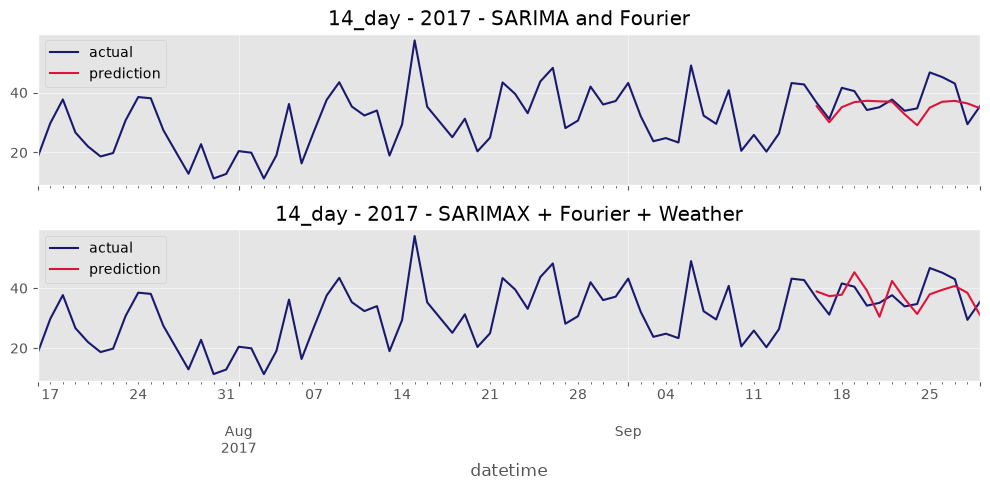

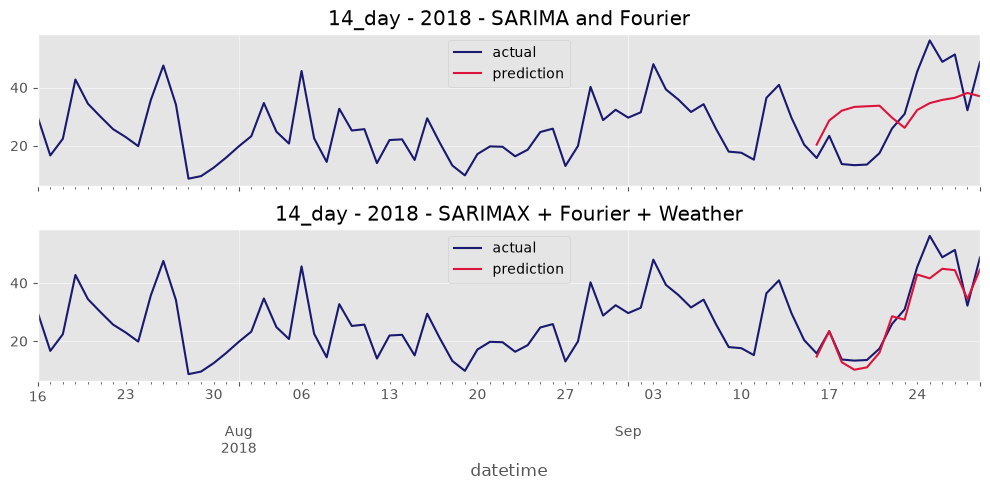

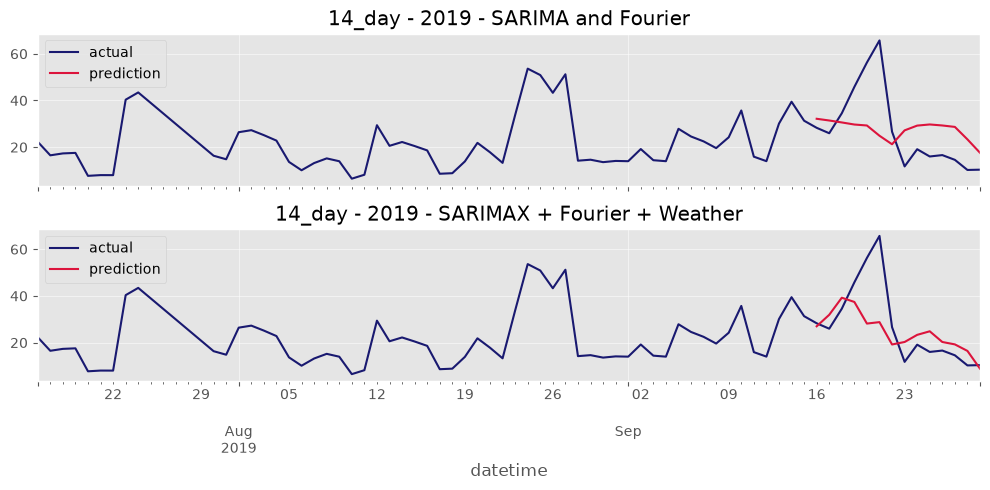

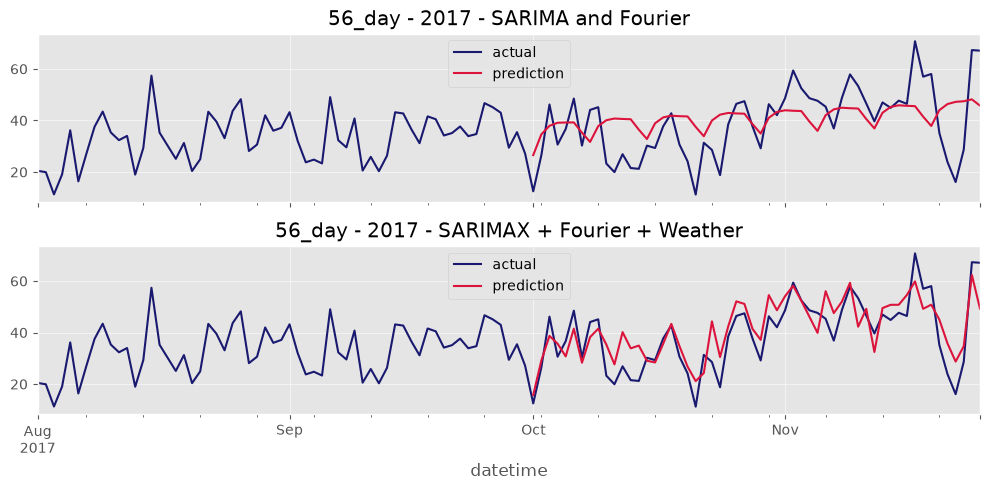

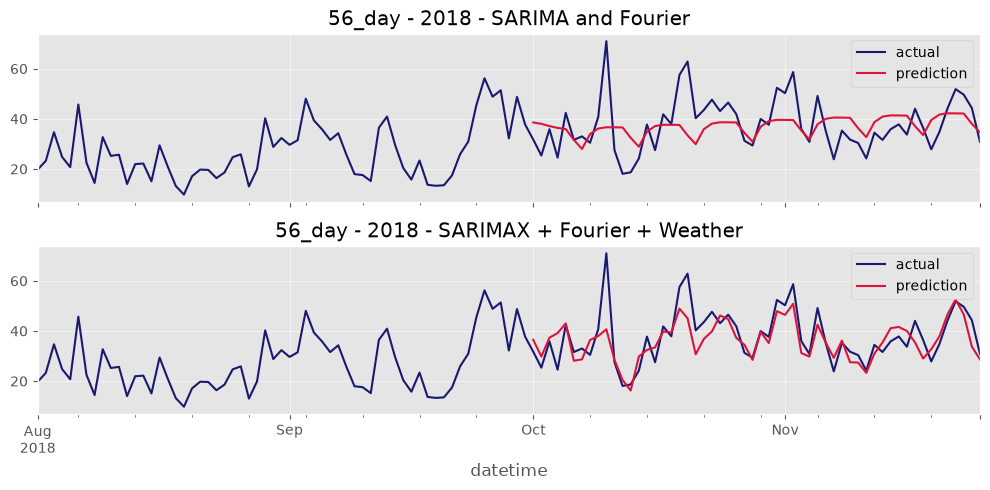

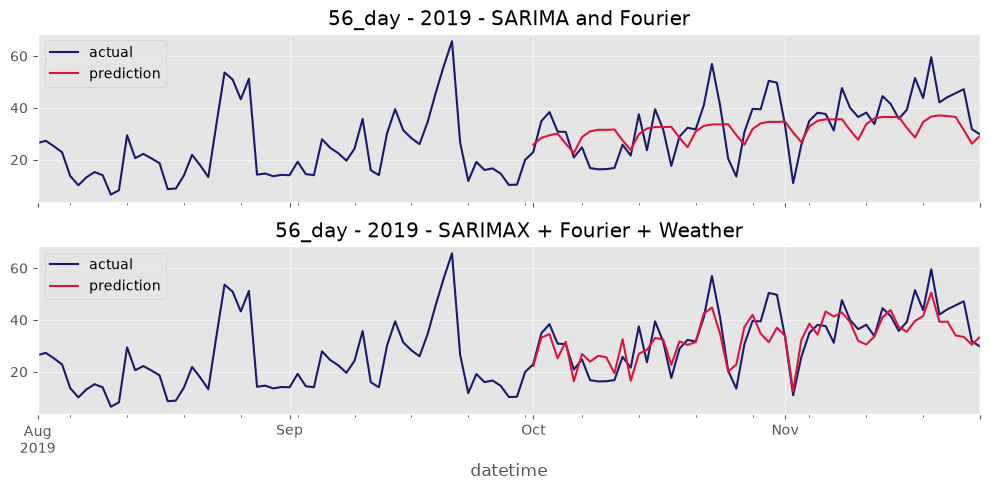

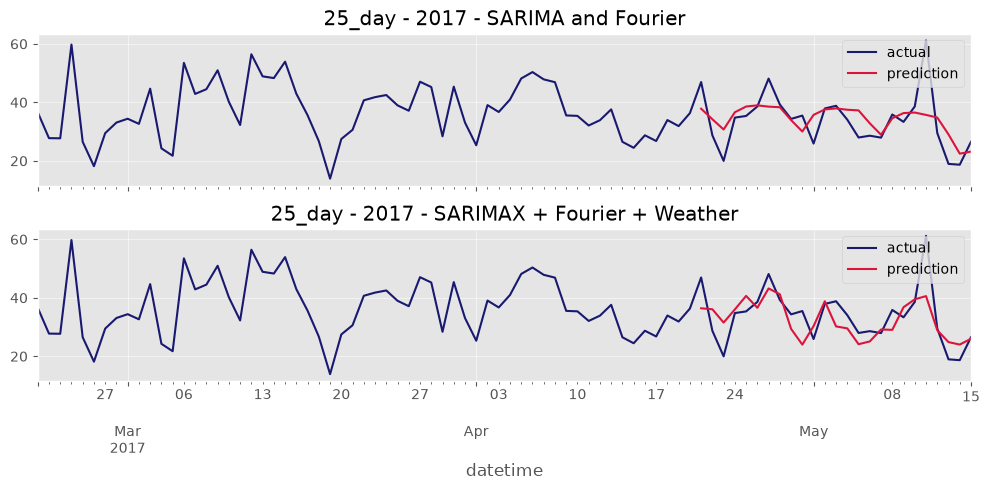

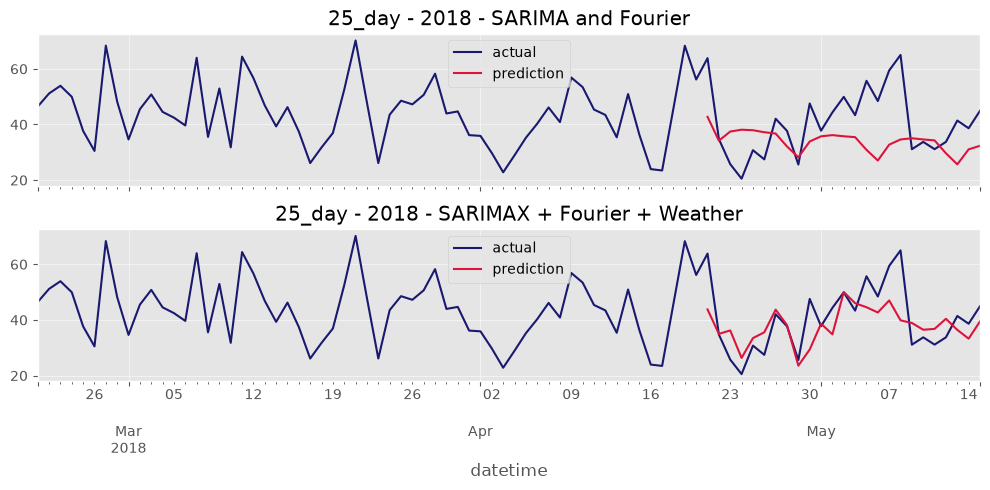

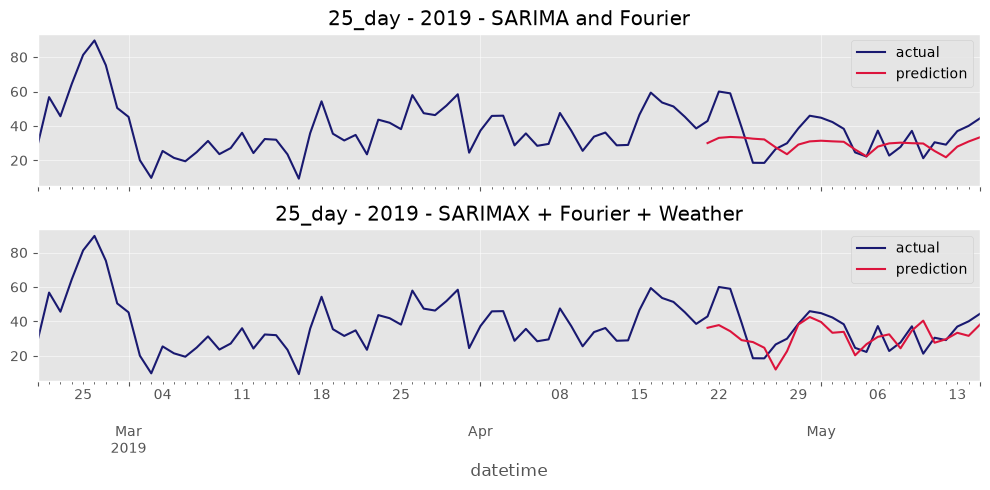

In [102]:
weather_predictions_df = weather_predictions_df.loc[(weather_predictions_df["pdq"] == best_pdq) & (weather_predictions_df["seasonal_pdq"] == best_s_pdq)].copy()

for gap, years in arima_tests.items():
    for year, test_period in years.items():

        fig, axes = plt.subplots(2,1, figsize = (10,5), sharex = True)


        plot_predictions(
            scope,
            model.loc[test_period.index, "prediction"],
            test_period,
            x_length="2_months",
            ax=axes[0]
        )

        plot_predictions(
            scope,
            weather_predictions_df.loc[test_period.index, "prediction"],
            test_period,
            x_length="2_months",
            ax=axes[1]
        )

        axes[0].set_title(f"{gap} - {year} - SARIMA and Fourier")
        axes[1].set_title(f"{gap} - {year} - SARIMAX + Fourier + Weather")

        plt.tight_layout()
        plt.show()



I'm really happy with these results. The model now follows the variance of the data. I will impute all missing gaps in scope and prepare for forecasting

In [103]:
check_gaps(scope)



['2020-09-16 00:00:00 to 2020-09-29 00:00:00: 14 days',
 '2020-10-01 00:00:00 to 2020-11-25 00:00:00: 56 days',
 '2022-04-21 00:00:00 to 2022-05-15 00:00:00: 25 days',
 '2022-08-04 00:00:00 to 2022-08-14 00:00:00: 11 days']

In [104]:
print(scope.loc[scope['no2_level'].isna() == True, "no2_level"].index)

DatetimeIndex(['2020-09-16', '2020-09-17', '2020-09-18', '2020-09-19',
               '2020-09-20', '2020-09-21', '2020-09-22', '2020-09-23',
               '2020-09-24', '2020-09-25',
               ...
               '2022-08-05', '2022-08-06', '2022-08-07', '2022-08-08',
               '2022-08-09', '2022-08-10', '2022-08-11', '2022-08-12',
               '2022-08-13', '2022-08-14'],
              dtype='datetime64[us]', name='datetime', length=106, freq=None)


In [105]:
def impute_NaN_with_sarimax(full_data, best_pdq, best_s_pdq, exog):

    real_gaps = full_data["no2_level"].isna()

    model = SARIMAX(full_data["no2_level"],
                    order = best_pdq,
                    seasonal_order = best_s_pdq ,
                    exog = exog)

    fitted = model.fit(disp=False)

    predictions = fitted.get_prediction(start=full_data.index[0],
                                        end=full_data.index[-1],
                                        information_set= "smoothed").predicted_mean



    full_data.loc[real_gaps,"no2_level"] = predictions.loc[real_gaps]

    return real_gaps, full_data



In [106]:
real_gaps, full_data_filled = impute_NaN_with_sarimax(scope, best_pdq, best_s_pdq, exog)

/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [107]:
print(full_data_filled.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 3155 entries, 2015-01-01 to 2023-08-21
Freq: D
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   no2_level  3155 non-null   float64
 1   no2_diff   3044 non-null   float64
dtypes: float64(2)
memory usage: 203.0 KB
None


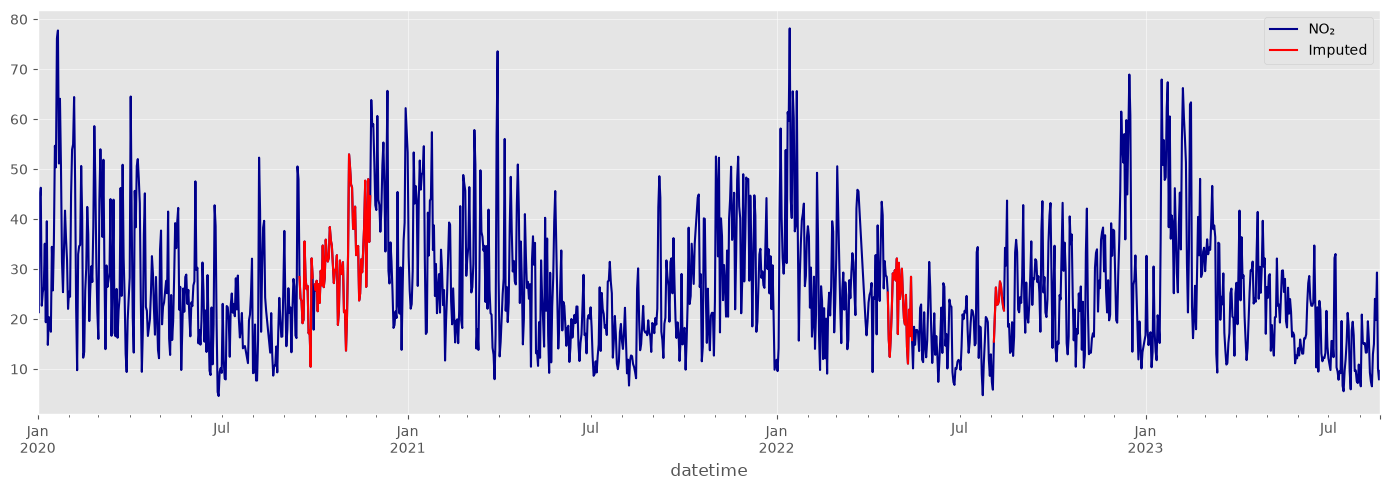

In [108]:
series = full_data_filled.loc["2020-01-01":,"no2_level"]
gap_mask = series.index.isin(real_gaps)

ax = series.plot(
    figsize=(14, 5), color="darkblue", label="NO₂"
)

series.where(real_gaps).plot(
    ax=ax,
    color= "red",
    label="Imputed"
)

ax.legend()
plt.tight_layout()
plt.show()

With our gaps filled. I will create a manual train test split and a cross validation, and test this model for forecasting.

# FORECASTING

for the forecasting part, In this experiment we are assuming the imputed values from before are ground truth.

In [109]:
def create_train_test(dataset, pct: float = 0.8):
    """Takes a df and the percentage of split in decimals """
    split = int(len(dataset) * pct)
    train = full_data_filled[:split]
    test = full_data_filled[split:]

    return train, test




In [110]:
fc_train, fc_test = create_train_test(full_data_filled, 0.8)

In [111]:
test_dict = {"80/20 split": {'test' : fc_test}}

In [112]:
full_data_filled.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 3155 entries, 2015-01-01 to 2023-08-21
Freq: D
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   no2_level  3155 non-null   float64
 1   no2_diff   3044 non-null   float64
dtypes: float64(2)
memory usage: 203.0 KB


I will run the pipleline

In [113]:
grid_results = grid_search_parameters(pdq, seasonal_pdq, fc_train['no2_level'], exog)

/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = s

Grid search finished


In [114]:
top_forecasters = create_selection(grid_results, 3)

In [115]:
print(top_forecasters.iloc[0,2])

(2, 1, 1, 7)


In [116]:
pdq = top_forecasters.iloc[0,1]
seasonal_pdq = top_forecasters.iloc[0,2]


Below im executing a walk forward validation in steps of 14 days, as that is going to be my forecasting horizon, I can also get 14 days of forecasting weather data from the API. note: this has a pretty high compute cost. With the current settings 18 minutes.

In [117]:
history = fc_train.copy()
forecast_horizon = 14

results_total = []
predictions_total = []

for start in range(0, len(fc_test), forecast_horizon):
    test_window = fc_test.iloc[start:start + forecast_horizon].copy()

    test_dict = {f"{start}": {'test' : test_window['no2_level']}}

    results, predictions = eval_model(top_forecasters, history, test_dict, "forecast", exog)

    results_total.append(results)
    predictions_total.append(predictions)
    history = pd.concat([history, test_window])

results_total = pd.concat(results_total)
predictions_total = pd.concat(predictions_total)



/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/Users/mathiasvandenbossche/PycharmProjects/LondonPollution/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimizat

In [118]:
results_total = results_total.drop(columns=["gap"])

In [119]:

model_performance = results_total.groupby(['pdq', 'seasonal_pdq']).mean()

best_pdq = results_total.iloc[0,0]
best_s_pdq = results_total.iloc[0,1]

print(f"the model with the best performance for forecasting = {best_pdq}, {best_s_pdq}.")



the model with the best performance for forecasting = (1, 1, 1), (2, 1, 1, 7).


In [120]:
last_5_tests = predictions_total['gap'].unique()[-6:-1]

mask = predictions_total[(predictions_total['pdq'] == best_pdq) & (predictions_total['seasonal_pdq'] == best_s_pdq) &
                  (predictions_total['gap'].isin(last_5_tests))]

mask = mask.set_index('date')

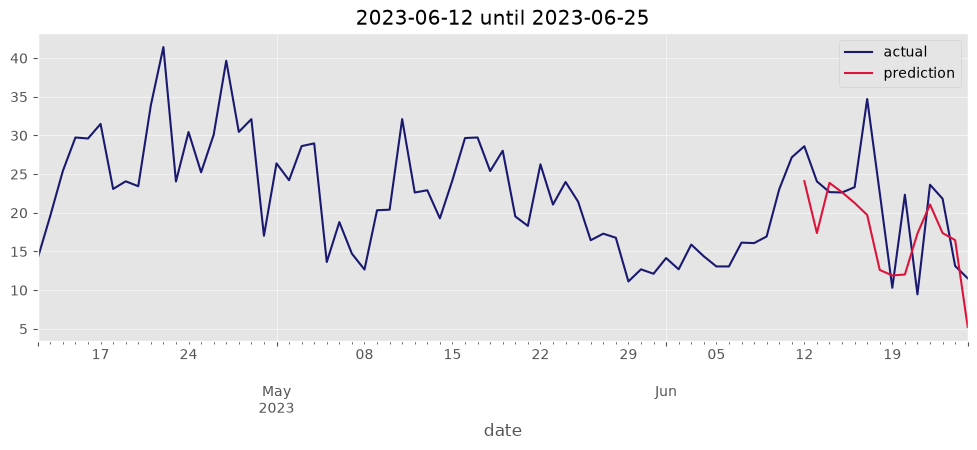

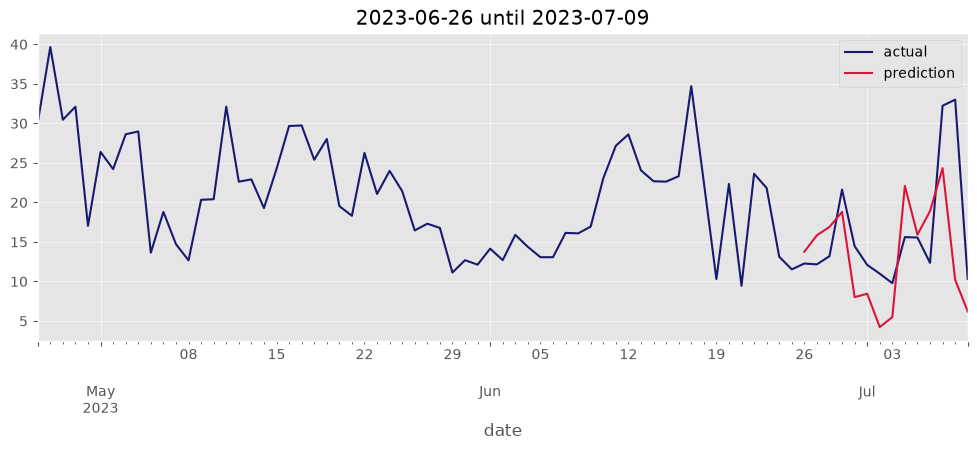

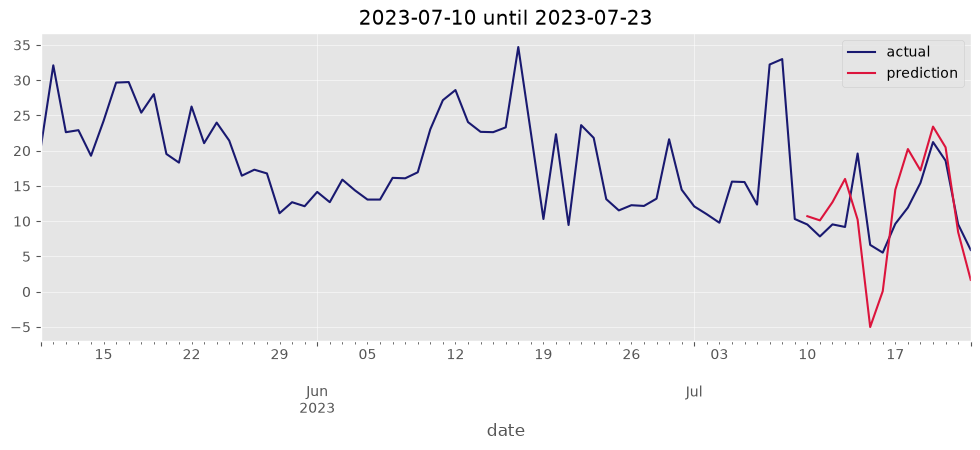

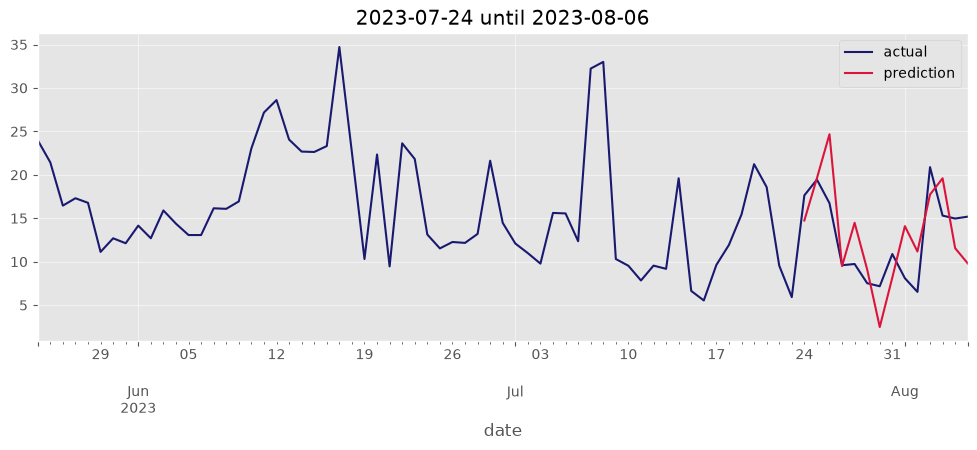

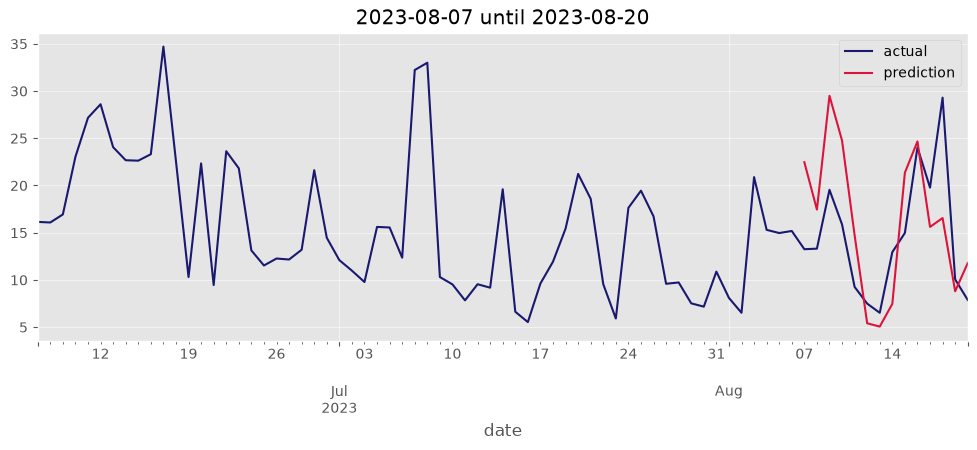

In [121]:


periods = mask["gap"].unique()

for gap in periods:

    plot_predictions(real_data= full_data_filled,
                     predictions= mask.loc[mask["gap"] == gap, "prediction"],
                     test= mask.loc[mask["gap"] == gap, "actual"],
                     x_length = "2_months")



In [122]:
model_performance

MAE      RMSE      MAPE
pdq       seasonal_pdq                              
(1, 1, 1) (2, 1, 1, 7)  5.563946  6.791932  0.263915
(2, 1, 2) (0, 1, 1, 7)  5.571549  6.790909  0.266042
          (2, 1, 1, 7)  5.565634  6.783952  0.264186

When we inspect the different test periods, we can see that the model can accurately predict the swings of the data. When I started this journey and went along different methods, I was not sure if I was going to reach a satisfactory result. In the end I'm very glad of the result its seems that when the data is anchored to a weather forecast, we could get seemingly accurate daily expectations based on the accuracy of the weather-forecast. Next to that, the models evaluated in this notebook already did catch a good part of the seasonality and the trend.

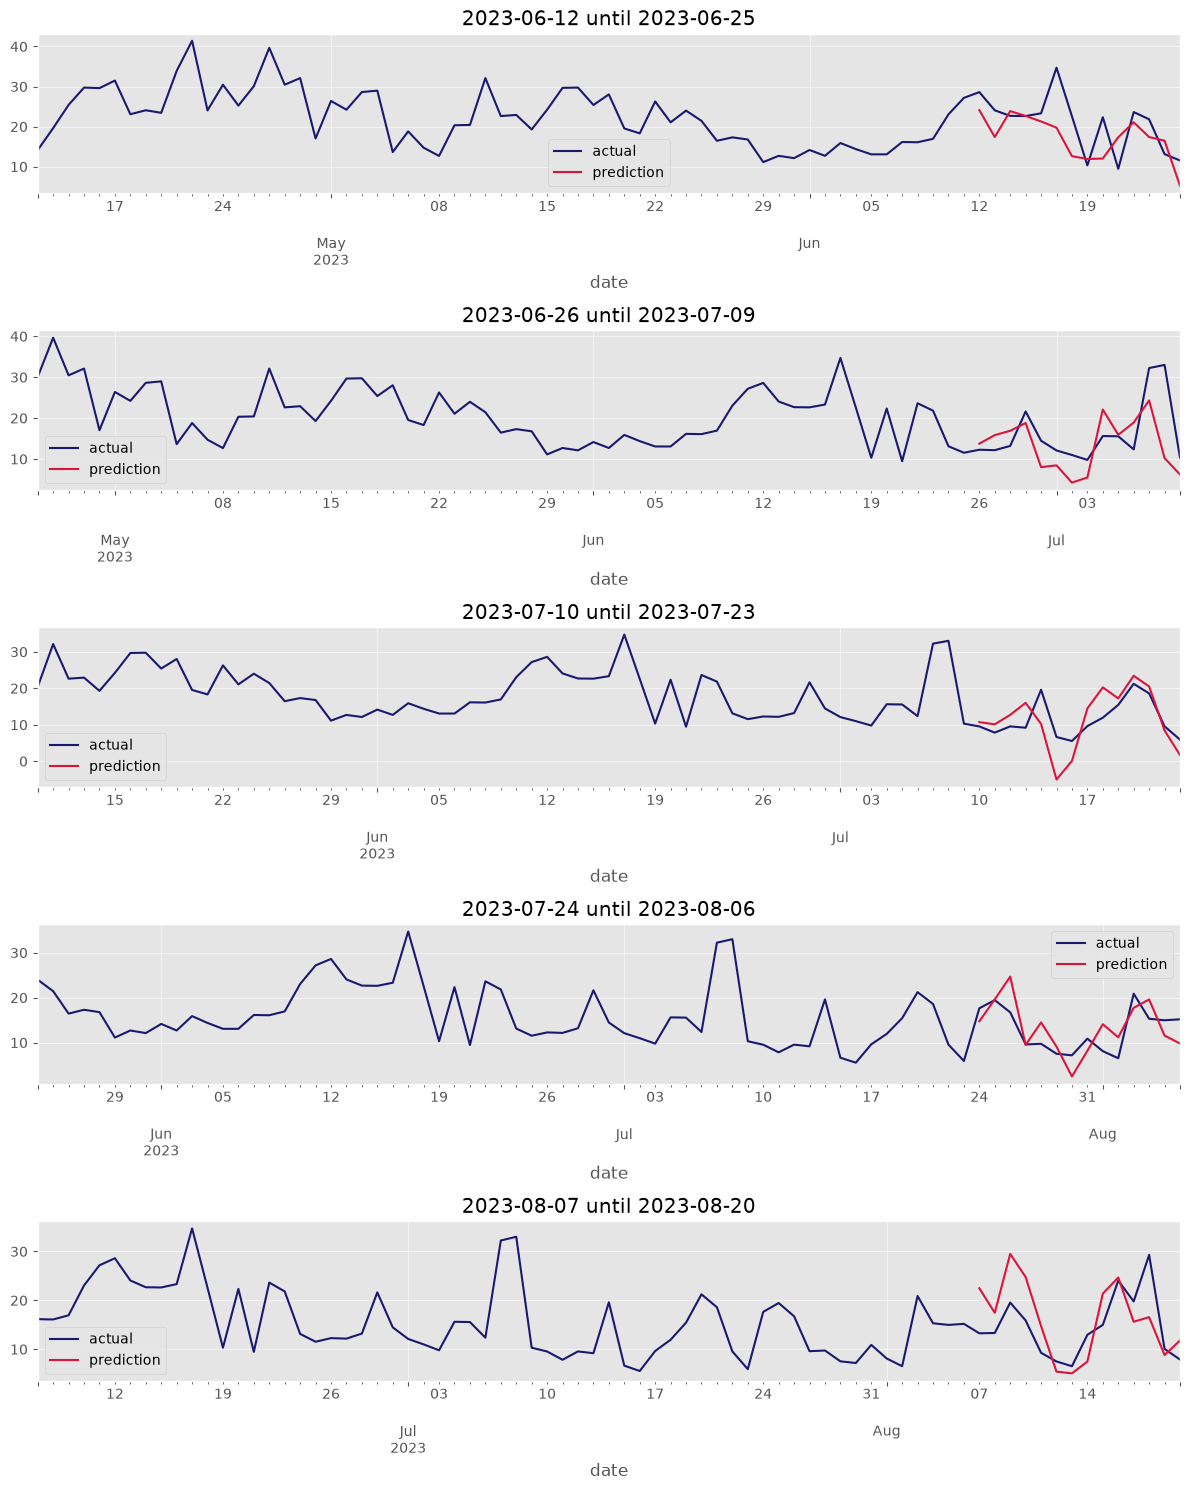

In [123]:


fig, axes = plt.subplots(
    len(periods), 1,
    figsize=(12, 3 * len(periods)),
    squeeze=False
)

for gap, ax in zip(periods, axes[:, 0]):
    window = mask.loc[mask["gap"] == gap]

    plot_predictions(
        real_data=full_data_filled,
        predictions=window["prediction"],
        test=window["actual"],
        x_length="2_months",
        ax=ax
    )

plt.tight_layout()
plt.show()